In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve
from scipy.optimize import approx_fprime
from scipy.optimize import root_scalar
from scipy.optimize import root
from scipy.optimize import least_squares
from numdifftools import Gradient
from numdifftools import Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu
from RMFsolver.Solver import RMFpressureSYM
from RMFsolver.Solver import RMFpressurePNM
from RMFsolver.Solver import pressure_RMF

from RMFsolver.phase_velocity import P_f, n_B, PQM, _vNtoQ_formula, vNtoQ_nc

n0 = 0.16 * const.MeV_fm**3

def PNM(mu_B, Temp, param=para.paraQMCRMF3, ):
    pre = RMFpressurePNM(
        input_num = mu_B,
        input_type = "muB", 
        Trmf = Temp, 
        para = param, 
        sigma_init = 30, 
        w0_init = 20, 
        r03_init = -3, 
        mub_init = 990,
        verb = False
        )
    return float(pre.item())

In [2]:
#B_SQM = 180
Pc_list = [1e8, 2e+8, 3e+8, 4e+8]
m_s = 0
Te = 70
N = 20

P_QM = []
P_NM = []
muB_list_list = []
muB_crit_list = []

for i in range(len(Pc_list)):
    # solve for critical point
    P_diff = lambda x: PNM(x, Te) - Pc_list[i]
    muB_crit = fsolve(P_diff, 1050)[0]
    PQM_solve_for_B = lambda x: PQM(muB_crit, 0, x, Te, m_s) - Pc_list[i]
    B_SQM = fsolve(PQM_solve_for_B, 180)
    muB_crit_list.append(muB_crit)

    muB_list = np.linspace(muB_crit-90, muB_crit+100, N)
    muB_list_list.append(muB_list)
    tmp_QM = []
    tmp_NM = []
    for mub in muB_list:
        tmp_QM.append(PQM(muB=mub, muK=0, B_one_forth=B_SQM, T=Te, ms=m_s, ))
        tmp_NM.append(PNM(mu_B = mub, Temp=Te, ))
    
    P_QM.append(tmp_QM)
    P_NM.append(tmp_NM)

/var/folders/zx/mchmm24s5sj4l19_jxvlkj380000gn/T/ipykernel_97717/3933969590.py:9: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10')


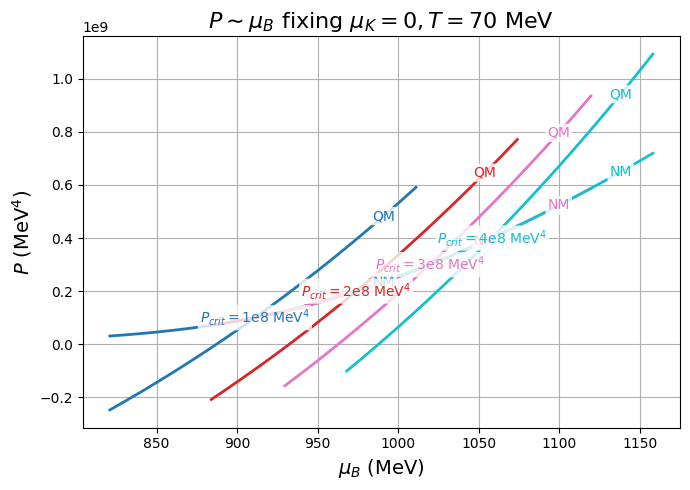

In [4]:
# Plot
import matplotlib.cm as cm
import os
import matplotlib.colors as colors

plt.figure(figsize=(7, 5))

norm = colors.Normalize(vmin=np.array(Pc_list).min(), vmax=np.array(Pc_list).max())
cmap = cm.get_cmap('tab10')

# Tight background box
boxprops = dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor='none', alpha=0.8)



for i in range(len(Pc_list)):
    plt.plot(muB_list_list[i], P_NM[i], lw=2, color=cmap(norm(Pc_list[i])))
    plt.plot(muB_list_list[i], P_QM[i], lw=2, color=cmap(norm(Pc_list[i])))
    plt.text(muB_list_list[i][-3], P_QM[i][-3], "QM", color=cmap(norm(Pc_list[i])), ha='center', va='center', bbox=boxprops)
    plt.text(muB_list_list[i][-3], P_NM[i][-3], "NM", color=cmap(norm(Pc_list[i])), ha='center', va='center', bbox=boxprops)
    plt.text(muB_crit_list[i], Pc_list[i], r"$P_{crit}=$"+format(Pc_list[i], '.0e').replace('+0', '').replace('+', '')+r" MeV$^4$", color=cmap(norm(Pc_list[i])), ha='center', va='center', bbox=boxprops)

plt.xlabel(r'$\mu_B$ (MeV)', fontsize=14)
plt.ylabel(r'$P$ (MeV$^4$)', fontsize=14)
plt.title(r'$P\sim\mu_B$ fixing $\mu_K = 0, T=$'+str(Te)+' MeV', fontsize=16)
plt.grid(True)
plt.tight_layout()


# Define the path to the Downloads folder
#downloads_path = os.path.expanduser("/Users/janshao/Downloads/")

# Save the figure
#plt.savefig(os.path.join(downloads_path, "P-muB-1.pdf"), dpi=300)

In [7]:
from RMFsolver.phase_velocity import Get_Two_as_dens

nc_list = np.linspace(2*n0, 4*n0, 10)

Tem = 50
Delta_n = 0.5*n0

a_Qstar = []
a_N = []

for i in range(len(nc_list)):
    tmp_Qstar, tmp_N = Get_Two_as_dens(
        T = Tem,
        n_crit = nc_list[i],
        Deln = Delta_n, 
        m_s = 0, 
        param = para.paraQMCRMF3,
        NM_type = "PNM",
    )
    a_Qstar.append(tmp_Qstar)
    a_N.append(tmp_N)
    print(i)

0
1
2
3
4
5
6
7
8
9


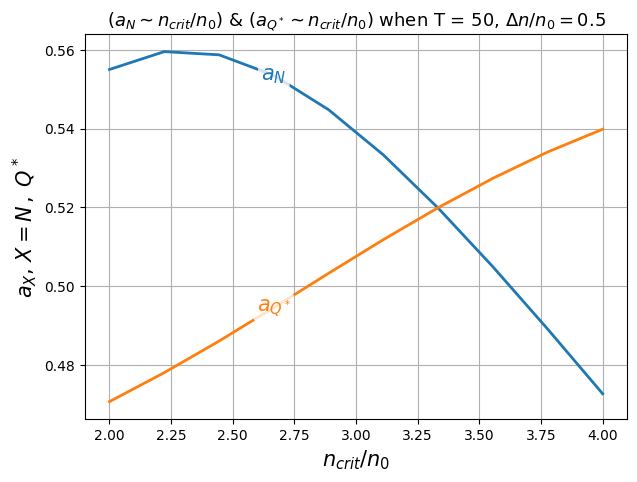

In [8]:
plt.figure(figsize=(7, 5))
plt.plot(nc_list/n0, a_N, lw=2, color='tab:blue')
plt.plot(nc_list/n0, a_Qstar, lw=2, color='tab:orange')
plt.plot()
#plt.plot(nc_list, np.ones(10), '--k', lw=1.2)


# Tight background box
boxprops = dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor='none', alpha=0.8)

plt.text(nc_list[3]/n0, a_N[3], r"$a_N$", fontsize=15, color='tab:blue', ha='center', va='center', bbox=boxprops)
plt.text(nc_list[3]/n0,  a_Qstar[3],  r"$a_{Q^*}$", fontsize=15, color='tab:orange', ha='center', va='center', bbox=boxprops)


plt.xlabel(r"$n_{crit}/n_0$", fontsize=15)
plt.ylabel(r"$a_{X}$, $X=N\,,\;Q^*$", fontsize=15)
plt.title(r"$(a_N\sim n_{crit}/n_0)$ & $(a_{Q^*}\sim n_{crit}/n_0)$ when T = "+str(Tem)+r", $\Delta n/n_0 = 0.5$", fontsize=13)

plt.grid(True)

#downloads_path = os.path.expanduser("/Users/janshao/NSM_related/muK_0")

#plt.savefig(os.path.join(downloads_path, "aX_T_B="+str(B_of)+"_DelP="+format(DeltaP, '.0e').replace('+0', '').replace('+', '')+".pdf"), dpi=300)

In [2]:
v, _ = vNtoQ_nc(
    T = 10,
    n_crit = 3.0 * n0,
    Deln = 0.5 * n0,
    m_s = 0,
    param = para.paraQMCRMF3,
    NM_type = "PNM"
)
v

np.float64(275.78862607152973)

In [ ]:
275.79092938853034

In [7]:
v, _ = vNtoQ_nc(
    T = 100,
    n_crit = 2.0 * n0,
    Deln = 0.5 * n0,
    m_s = 0,
    param = para.paraQMCRMF3,
    NM_type = "PNM"
)
v

hit aN < aQstar, returning velocity = 0


0.0

In [ ]:
83817.22619686672

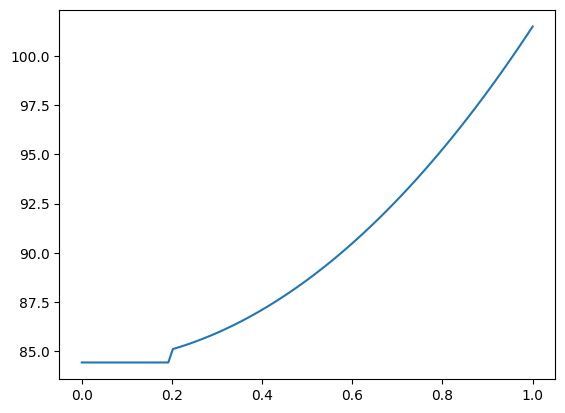

In [26]:
Tem = np.linspace(0.0, 1, 100)
PP = np.array([P_f(10, 0, Tem[i]) for i in range(100)])
nn = np.array([n_B(10, 0, Tem[i]) for i in range(100)])

plt.plot(Tem, PP)

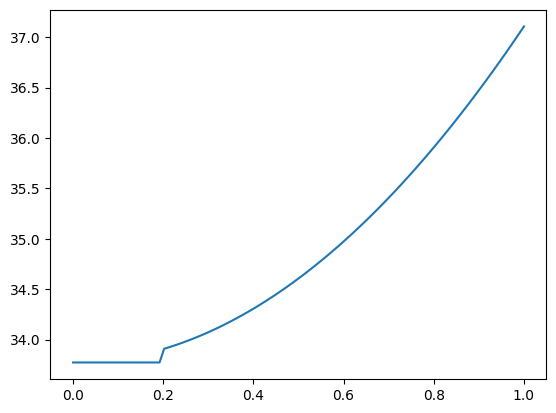

In [27]:
plt.plot(Tem, nn)

In [1]:
import numpy as np
from scipy.integrate import quad

# ============ the one shared helper ============
def _smooth_weight(T: float, mu: float, m: float, T0: float = 0.2, sharp: float = 2.0) -> float:
    """
    Logistic blend weight w ∈ [0,1] for switching:
      w≈0 → use Sommerfeld (low-T, highly degenerate)
      w≈1 → use exact finite-T integral
    """
    tiny = 1e-12
    # degeneracy gate
    delta = (mu - m) / max(T, tiny)
    x = np.clip(delta - 8.0, -700.0, 700.0)
    w_deg = 1.0 / (1.0 + np.exp(x))   # ~0 when μ−m ≫ T

    # temperature gate (transition width ~ T0/sharp)
    y = np.clip(-(T - T0)*sharp/T0, -700.0, 700.0)
    w_T  = 1.0 / (1.0 + np.exp(y))    # ~0 when T ≪ T0

    w = 1.0 - (1.0 - w_deg)*(1.0 - w_T)
    return float(np.clip(w, 0.0, 1.0))

# =================== free-fermion pressure ===================

def P_f(mu, m, Tem, upB=np.inf):
    """
    Pressure for one free fermion species (incl. antiparticles).
    Smooth across T→0 via logistic blend.
    """
    mu = float(mu); m = float(m); Tem = float(Tem)

    # ---- local (free-gas) building blocks kept here on purpose ----
    def kF(mu, m):
        return np.sqrt(max(mu*mu - m*m, 0.0))

    def P0(mu, m):
        if mu <= m:
            return 0.0
        if m == 0.0:
            return mu**4 / (12.0*np.pi**2)
        k = kF(mu, m)
        return ((2.0*k**3 - 3.0*m*m*k)*mu + 3.0*m**4*np.log((k+mu)/m)) / (24.0*np.pi**2)

    def f_at_mu(mu, m):
        # dP/d(μ) at T=0 entering Sommerfeld O(T^2)
        if mu <= m:
            return 0.0
        if m == 0.0:
            return (mu*mu) / (np.pi**2)
        return (mu * kF(mu, m)) / (np.pi**2)

    def press_integrand(k, mu, m, T):
        Ek = np.sqrt(k*k + m*m)
        a  = (Ek - mu)/T
        b  = (Ek + mu)/T
        arg  = T*np.log1p(np.exp(-np.clip(a, -700.0, 700.0)))
        argb = T*np.log1p(np.exp(-np.clip(b, -700.0, 700.0)))
        return (arg + argb) * k*k

    # ---- branches ----
    if Tem <= 0.0:
        return P0(mu, m)

    P_low = P0(mu, m) + (np.pi**2/6.0) * Tem*Tem * f_at_mu(mu, m)

    ub = np.inf if (upB is None or np.isinf(upB)) else float(upB)
    Pint, _ = quad(lambda k: press_integrand(k, mu, m, Tem),
                   0.0, ub, epsabs=1e-10, epsrel=1e-8)
    P_int = Pint / (np.pi**2)

    w = _smooth_weight(Tem, mu, m, T0=0.2, sharp=2.0)
    return (1.0 - w)*P_low + w*P_int

# =================== free-fermion number density ===================

def n_B(mu, m, Tem, upB=np.inf):
    """
    Number density for one free fermion species (particles − antiparticles).
    Smooth across T→0 via logistic blend.
    """
    mu = float(mu); m = float(m); Tem = float(Tem)

    # ---- local (free-gas) building blocks kept here on purpose ----
    def kF(mu, m):
        return np.sqrt(max(mu*mu - m*m, 0.0))

    def n0(mu, m):
        if mu <= m:
            return 0.0
        if m == 0.0:
            return mu**3 / (3.0*np.pi**2)
        return kF(mu, m)**3 / (3.0*np.pi**2)

    def fp_at_mu(mu, m):
        # dn/dμ at T=0 entering Sommerfeld O(T^2)
        if mu <= m:
            return 0.0
        if m == 0.0:
            return (2.0*mu) / (np.pi**2)
        k = kF(mu, m)
        return (2.0*mu*mu - m*m) / (np.pi**2 * max(k, 1e-300))

    def dens_integrand(k, mu, m, T):
        Ek  = np.sqrt(k*k + m*m)
        fa  = 1.0/(1.0 + np.exp(np.clip((Ek - mu)/T, -700.0, 700.0)))
        fba = 1.0/(1.0 + np.exp(np.clip((Ek + mu)/T, -700.0, 700.0)))
        return (fa - fba) * k*k

    # ---- branches ----
    if Tem <= 0.0:
        return n0(mu, m)

    n_low = n0(mu, m) + (np.pi**2/6.0) * Tem*Tem * fp_at_mu(mu, m)

    ub = np.inf if (upB is None or np.isinf(upB)) else float(upB)
    Nint, _ = quad(lambda k: dens_integrand(k, mu, m, Tem),
                   0.0, ub, epsabs=1e-10, epsrel=1e-8)
    n_int = Nint / (np.pi**2)

    w = _smooth_weight(Tem, mu, m, T0=0.2, sharp=2.0)
    return (1.0 - w)*n_low + w*n_int

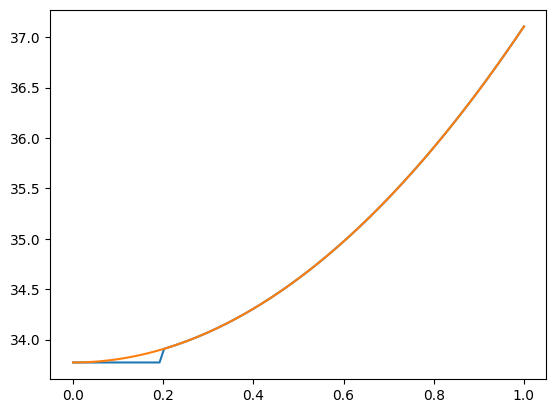

In [3]:
from RMFsolver.phase_velocity import _P_f_old, _n_B_old#, P_f, n_B
import matplotlib.pyplot as plt

Tem = np.linspace(0.00, 1, 100)
non = np.array([_n_B_old(10, 0, Tem[i]) for i in range(100)])
smooth = np.array([n_B(10, 0, Tem[i]) for i in range(100)])

plt.plot(Tem, non)
plt.plot(Tem, smooth)


# Calculate the gray region again under log scale

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from RMFsolver.phase_velocity import Get_Two_as_dens
from tqdm import tqdm

N = 30
nc = 2*n0
m_strange = 0

TT = np.logspace(np.log10(0.01), np.log10(100), N) #np.hstack([np.linspace(1, 20, int(N*2/5)),np.linspace(20.5, 72, int(N*3/5))])
DD = np.linspace(0.01*n0, 0.5*n0, N)

a_diff = np.zeros([N, N])

for i in tqdm(range(N), desc="Computing for 2 n0"):  # loop over T (rows)
    for j in range(N):  # loop over B (columns)
        aQ_tmp, aN_tmp = Get_Two_as_dens(
            T = TT[i],
            n_crit = nc,
            Deln = DD[j],
            m_s = m_strange,
            param = para.paraQMCRMF3,
            NM_type = "PNM",
        )
        a_diff[i,j] = aN_tmp - aQ_tmp
        #print(i, j, a_diff[i,j])

#np.save("aQstar_aN_n_crit="+str(nc/n0)+"log.npy", a_diff)

Computing for 2 n0: 100%|████████████████████| 30/30 [1:24:59<00:00, 169.99s/it]


Text(0, 0.5, 'T  (MeV)')

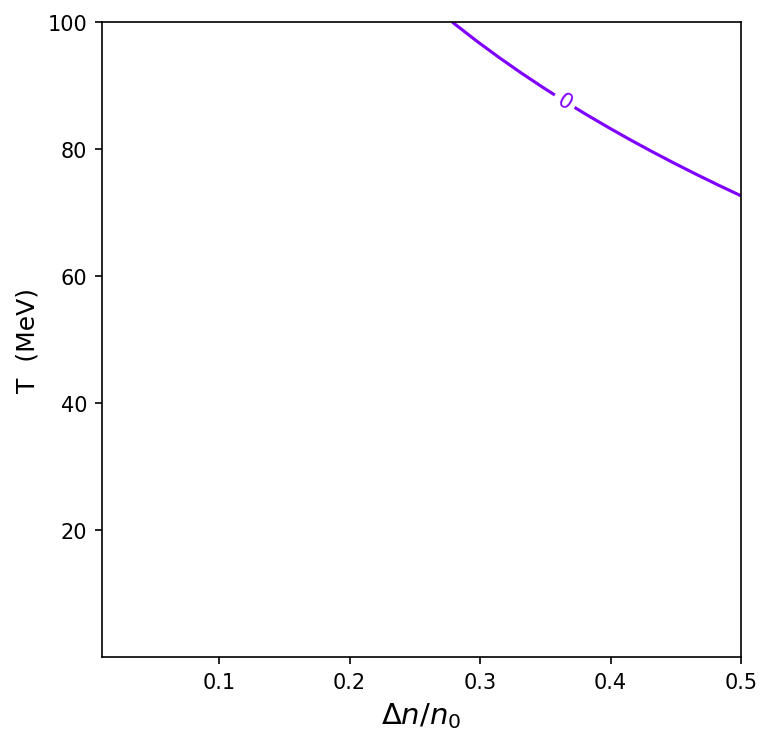

In [32]:
T_grid, D_grid = np.meshgrid(TT, DD)

plt.figure(figsize=[5.5, 5.5])
plt.rcParams["figure.dpi"] = 150

# Plotting
a_diff_new = np.load("/Users/janshao/Downloads/aQstar_aN_n_crit=2_log_field.npy")

#V_old = np.load("DelP_T_B180_ms100.npy")
#D_grid_old, T_grid_old = np.meshgrid(np.linspace(1e6, 1e8, N)/4e8, np.linspace(1, 30, N))

contours = plt.contour(D_grid/n0, T_grid, a_diff_new.T, levels = [0], cmap="rainbow")
plt.clabel(contours, inline=True, fontsize=10)

#plt.title(r"Contour of $v_{N\to Q}^{max}$ in ($m\cdot s^{-1}$) for $n_{crit}=$"+str(nc/n0)+r"$n_0$" )
plt.xlabel(r"$\Delta n / n_{0}$", fontsize=14)
plt.ylabel("T  (MeV)", fontsize=12)

#plt.savefig("Deln_T_ncrit="+str(nc/n0)+".pdf", dpi=300)  # Increase DPI as needed

In [41]:
import numpy as np
import matplotlib.pyplot as plt
from RMFsolver.phase_velocity import Get_Two_as_dens
from tqdm import tqdm

N = 30
nc = 3*n0
m_strange = 0

TT = np.logspace(np.log10(0.01), np.log10(100), N) #np.hstack([np.linspace(1, 20, int(N*2/5)),np.linspace(20.5, 72, int(N*3/5))])
DD = np.linspace(0.01*n0, 0.5*n0, N)

a_diff3 = np.zeros([N, N])

for i in tqdm(range(N), desc="Computing for 3 n0"):  # loop over T (rows)
    for j in range(N):  # loop over B (columns)
        aQ_tmp, aN_tmp = Get_Two_as_dens(
            T = TT[i],
            n_crit = nc,
            Deln = DD[j],
            m_s = m_strange,
            param = para.paraQMCRMF3,
            NM_type = "PNM",
        )
        a_diff3[i,j] = aN_tmp - aQ_tmp
        #print(i, j, a_diff[i,j])

#np.save("aQstar_aN_n_crit="+str(nc/n0)+"log.npy", a_diff)

Computing for 3 n0: 100%|████████████████████| 30/30 [1:39:10<00:00, 198.34s/it]


Text(0, 0.5, 'T  (MeV)')

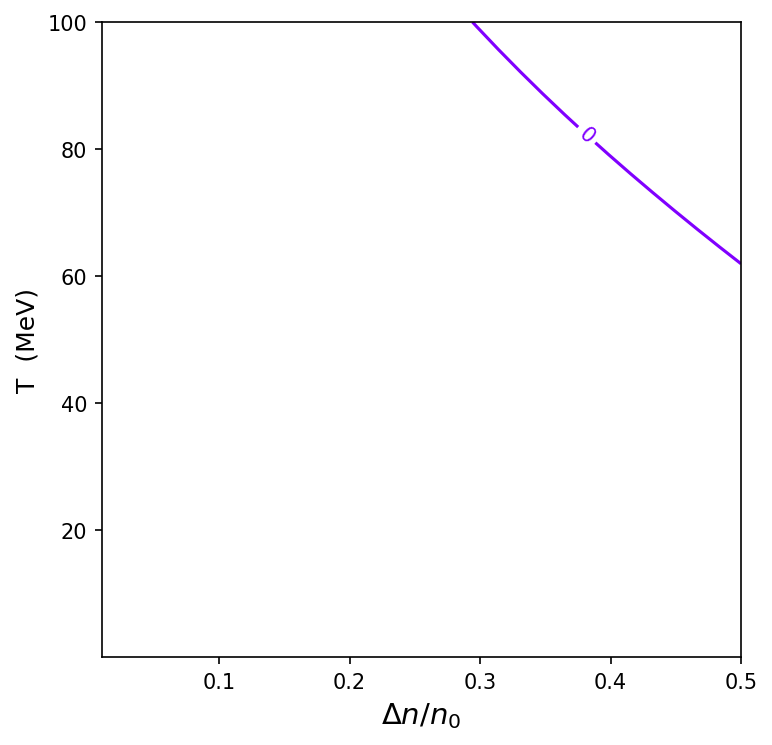

In [42]:
T_grid, D_grid = np.meshgrid(TT, DD)

plt.figure(figsize=[5.5, 5.5])
plt.rcParams["figure.dpi"] = 150

# Plotting
#a_diff_new = np.load("/Users/janshao/Downloads/aQstar_aN_n_crit=2_log_field.npy")

#V_old = np.load("DelP_T_B180_ms100.npy")
#D_grid_old, T_grid_old = np.meshgrid(np.linspace(1e6, 1e8, N)/4e8, np.linspace(1, 30, N))

contours = plt.contour(D_grid/n0, T_grid, a_diff3.T, levels = [0], cmap="rainbow")
plt.clabel(contours, inline=True, fontsize=10)

#plt.title(r"Contour of $v_{N\to Q}^{max}$ in ($m\cdot s^{-1}$) for $n_{crit}=$"+str(nc/n0)+r"$n_0$" )
plt.xlabel(r"$\Delta n / n_{0}$", fontsize=14)
plt.ylabel("T  (MeV)", fontsize=12)

#plt.savefig("Deln_T_ncrit="+str(nc/n0)+".pdf", dpi=300)  # Increase DPI as needed

In [27]:
from RMFsolver.phase_velocity import extract_contour_coords_num
Deln_cut, T_cut = extract_contour_coords_num(D_grid, T_grid, a_diff.T, level=0)
np.save("Shade_n_crit="+str(nc/n0)+"_log.npy", np.array([Deln_cut, T_cut]))

(0.01, 100.0)

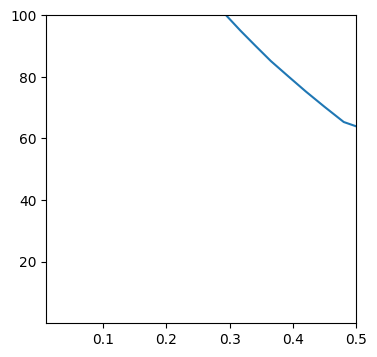

In [10]:
import numpy as np
import matplotlib.pyplot as plt

TT_log = np.logspace(np.log10(0.01), np.log10(1.0), num=40)
TT_lin = np.linspace(1.0, 100.0, num=21)[1:]   # 20 linear points excluding the 1.0 duplicate
TT = np.concatenate([TT_log, TT_lin])

[Deln, Tcut] = np.load("Shade_n_crit=3_TTpiece__v2.npy")
plt.figure(figsize=[4,4])
plt.plot(Deln/n0, Tcut)
plt.xlim(0.01, 0.5)
plt.ylim(0.01, 100)
#plt.yscale("log")

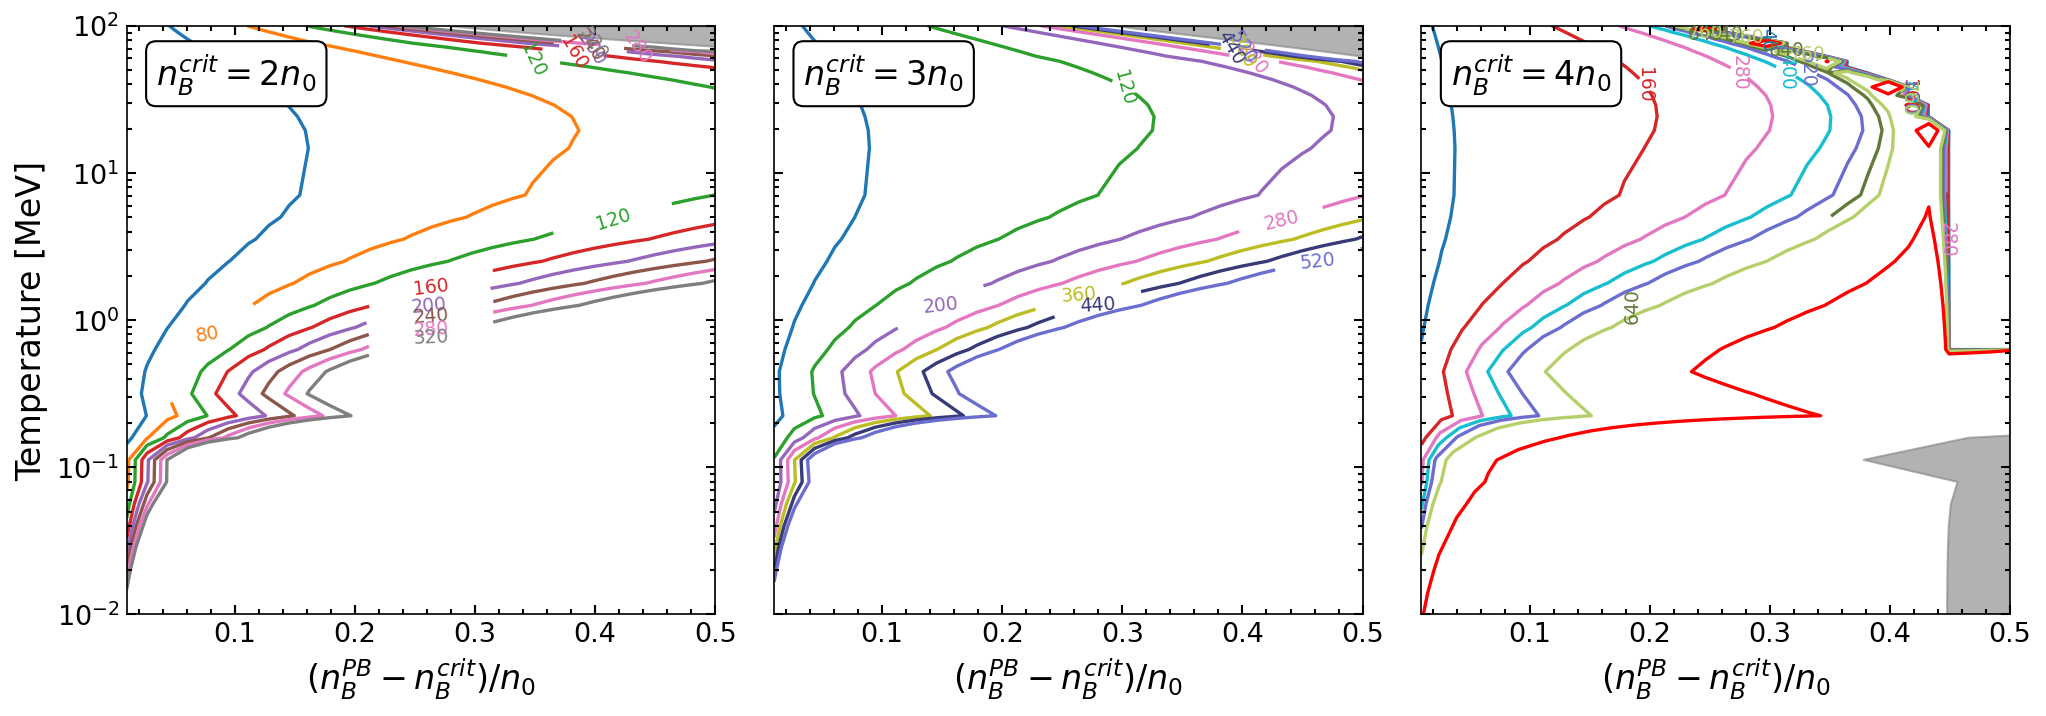

In [53]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.integrate import quad
from scipy.interpolate import interp1d
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, n_B, vNtoQ_nc, vNtoQ_B, PQM
import matplotlib.colors as mcolors
from matplotlib.colors import ListedColormap

# ------------------------------------------------------------
# Constants and grids
# ------------------------------------------------------------
n0 = 0.16 * const.MeV_fm**3
nc2, nc3, nc4 = 2*n0, 3*n0, 4*n0

# New TT sampling: 0.01→10 (log, 20 pts WITHOUT endpoint 10) + 10→100 (lin, 20 pts WITH 10)
TT_log = np.logspace(np.log10(0.01), np.log10(10.0), num=20, endpoint=False)
TT_lin = np.linspace(10.0, 100.0, num=20)[1:]
TT = np.concatenate([TT_log, TT_lin])     # length 40
NT = TT.size                               # rows (y-axis)

# DD grid: 30 points (x-axis)
M = 30
DD = np.linspace(0.01*n0, 0.5*n0, M)

al = 0.6

# shaded region boundaries (use *_TTpiece produced by the new sampling)
Deln_cut3, T_cut3 = np.load("Shade_n_crit=3_TTpiece.npy", allow_pickle=True)
Cut3 = interp1d(T_cut3, Deln_cut3, kind='linear', fill_value="extrapolate")

Deln_cut4, T_cut4 = np.load("Shade_n_crit=4_TTpiece.npy", allow_pickle=True)
Cut4 = interp1d(T_cut4, Deln_cut4, kind='linear', fill_value="extrapolate")

Deln_cut2, T_cut2 = np.load("Shade_n_crit=2_TTpiece.npy", allow_pickle=True)
Cut2 = interp1d(T_cut2, Deln_cut2, kind='linear', fill_value="extrapolate")

# ------------------------------------------------------------------------------------
# Levels per subplot
# ------------------------------------------------------------------------------------
levels_11 = np.array([40+40*i for i in range(8)])               # 8 levels (2 n0)
levels_12 = np.array([40+80*i for i in range(7)])               # 7 levels (3 n0)
levels_21 = np.array([*(40+120*i for i in range(7)), 2000])     # + special 2000 (4 n0)

ALL_LEVELS = np.unique(np.concatenate([levels_11, levels_12, levels_21]))

# ------------------- COLOR MAPPING -------------------
tab20 = plt.get_cmap("tab20").colors
sat = [tab20[i] for i in [0,2,4,6,8,10,12,14,16,18]]
tab20b = plt.get_cmap("tab20b").colors
tab20c = plt.get_cmap("tab20c").colors
palette = sat + list(tab20b[::2]) + list(tab20c[::2])
cmap = ListedColormap(palette, name="tab20_bright")
def pick(i): return cmap.colors[i % len(cmap.colors)]

LEVEL_COLOR = {lev: pick(k) for k, lev in enumerate(ALL_LEVELS)}
for s in (2000, 3000):
    LEVEL_COLOR[s] = (1,0,0,1)

def contour_with_fixed_colors(ax, X, Y, Z, levels, **kwargs):
    cols = [LEVEL_COLOR[lev] for lev in levels]
    cs = ax.contour(X, Y, Z, levels=levels, colors=cols, **kwargs)
    ax.clabel(cs, inline=True, fontsize=9, fmt="%d")
    return cs

# ================= 1 x 3 LAYOUT (square subplots) =================
fig, axs = plt.subplots(1, 3, figsize=(13.5, 4.8), sharey=True)
plt.subplots_adjust(left=0.05, right=0.98, bottom=0.12, top=0.95, wspace=0.10)
for ax in axs:
    ax.set_box_aspect(1)  # square axes

ax20, ax30, ax40 = axs  # 2n0, 3n0, 4n0

# ------------------------------------------------------------
# panel 1: n_crit = 2 n0
# ------------------------------------------------------------
V2 = np.load("v_n_crit=2_TTpiece.npy")     # expected shape (NT, M) = (40, 30)
t = np.linspace(0.0, 1.0, M)
Dlo = 0.01 * n0
Dhi = 0.5  * n0
Dmax = np.minimum(Dhi, Cut2(TT) - 0.015 * n0)
Dmax = np.maximum(Dmax, Dlo)
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]     # shape (NT, M)
T_grid = np.repeat(TT[:, None], M, axis=1)            # shape (NT, M)

Dcut = Cut2(TT)
ax20.fill_betweenx(TT, Dcut/n0, (0.5*n0)/n0, color="grey", alpha=al, zorder=0)
contour_with_fixed_colors(ax20, D_grid/n0, T_grid, V2, levels_11, linewidths=1.6, zorder=1)
ax20.set_xlim(0.01, 0.5)
ax20.set_ylim(0.01, 100)
ax20.annotate(r"$n_B^{crit} = 2 n_0$", xy=(0.05, 0.90), xycoords='axes fraction',
              fontsize=16, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

# ------------------------------------------------------------
# panel 2: n_crit = 3 n0
# ------------------------------------------------------------
V3 = np.load("v_n_crit=3_TTpiece.npy")     # (40, 30)
t = np.linspace(0.0, 1.0, M)
Dmax = np.minimum(Dhi, Cut3(TT) - 0.015 * n0)
Dmax = np.maximum(Dmax, Dlo)
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]
T_grid = np.repeat(TT[:, None], M, axis=1)

Dcut = Cut3(TT)
ax30.fill_betweenx(TT, Dcut/n0, (0.5*n0)/n0, color="grey", alpha=al, zorder=0)
contour_with_fixed_colors(ax30, D_grid/n0, T_grid, V3, levels_12, linewidths=1.6, zorder=1)
ax30.set_xlim(0.01, 0.5)
ax30.set_ylim(0.01, 100)
ax30.annotate(r"$n_B^{crit} = 3 n_0$", xy=(0.05, 0.90), xycoords='axes fraction',
              fontsize=16, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

# ------------------------------------------------------------
# panel 3: n_crit = 4 n0
# ------------------------------------------------------------
V4 = np.load("v_n_crit=4_TTpiece.npy")     # (40, 30)
t = np.linspace(0.0, 1.0, M)
Dmax = np.minimum(Dhi, Cut4(TT) - 0.015 * n0)
Dmax = np.maximum(Dmax, Dlo)
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]
T_grid = np.repeat(TT[:, None], M, axis=1)

Dcut = Cut4(TT)
ax40.fill_betweenx(TT, Dcut/n0, (0.5*n0)/n0, color="grey", alpha=al, zorder=0)
contour_with_fixed_colors(ax40, D_grid/n0, T_grid, V4, levels_21, linewidths=1.6, zorder=1)
ax40.set_xlim(0.01, 0.5)
ax40.set_ylim(0.01, 100)
ax40.annotate(r"$n_B^{crit} = 4 n_0$", xy=(0.05, 0.90), xycoords='axes fraction',
              fontsize=16, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

# ---------- axes labels & ticks ----------
ax20.set_ylabel("Temperature [MeV]", fontsize=16)
for ax in (ax20, ax30, ax40):
    ax.set_xlabel(r"$(n^{PB}_B - n^{crit}_B) / n_0$", fontsize=16)
    ax.minorticks_on()
    ax.tick_params(which='both', direction='in', top=True, right=True,
                   length=4.5, width=1.0, labelsize=13)
    ax.tick_params(which='minor', length=2.5)
    #ax.set_yscale("log")

# plt.savefig("1by3_Grid_TTpiece.pdf")
# plt.show()

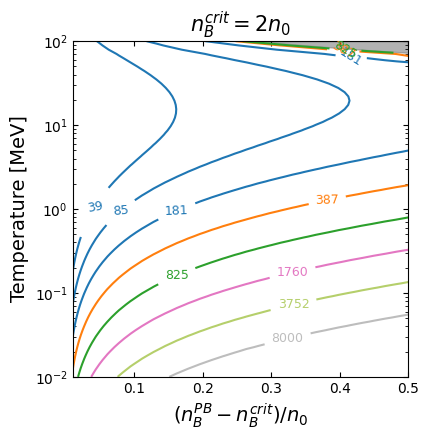

In [10]:
# core3_plot_min.py
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
import RMFsolver.constants as const
from matplotlib.colors import ListedColormap

# ------------------ constants ------------------
n0 = 0.16 * const.MeV_fm**3
nc3 = 3.0 * n0
al = 0.6  # shading alpha

# ------------------ same TT definition as used in solver ------------------
TT = np.logspace(np.log10(0.01), np.log10(100.0), num=80)
NT = TT.size

# Δn grid
N = 30
DD = np.linspace(0.01 * n0, 0.5 * n0, N)

# ------------------ load precomputed data ------------------
V3 = np.load("v_n_crit=2_TTpiece__v4.npy")  # shape (39, 30)
Deln_cut3, T_cut3 = np.load("Shade_n_crit=2_TTpiece__v4.npy", allow_pickle=True)
Cut3 = interp1d(T_cut3, Deln_cut3, kind="linear", fill_value="extrapolate")

# ------------------ build grids ------------------
t = np.linspace(0.0, 1.0, N)
Dlo = 0.01 * n0
Dhi = 0.5 * n0
Dmax = np.minimum(Dhi, Cut3(TT) - 0.015 * n0)
Dmax = np.maximum(Dmax, Dlo)
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]
T_grid = np.repeat(TT[:, None], N, axis=1)

# ------------------ plot ------------------
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.set_box_aspect(1)

# grey shaded region (unstable)
Dcut = Cut3(TT)
ax.fill_betweenx(TT, Dcut / n0, (0.5 * n0) / n0, color="grey", alpha=al)

# contour plot of velocity
levels = np.logspace(np.log10(40), np.log10(8000), 8)#np.concatenate([np.arange(40, 640, 80), [2000]])
tab20 = plt.get_cmap("tab20").colors
sat = [tab20[i] for i in [0,2,4,6,8,10,12,14,16,18]]
tab20b = plt.get_cmap("tab20b").colors
tab20c = plt.get_cmap("tab20c").colors
palette = sat + list(tab20b[::2]) + list(tab20c[::2])
cmap = ListedColormap(palette, name="tab20_bright")
def pick(i): return cmap.colors[i % len(cmap.colors)]
LEVEL_COLOR = {lev: pick(k) for k, lev in enumerate(levels)}
for s in (2000, 3000): LEVEL_COLOR[s] = (1,0,0,1)
cs = ax.contour(D_grid / n0, T_grid, V3, levels=levels, cmap = ListedColormap(palette, name="tab20_bright"), linewidths=1.5)
ax.clabel(cs, inline=True, fontsize=9, fmt="%d")

# labels and style
ax.set_xscale("linear")
ax.set_yscale("log")
ax.set_xlim(0.01, 0.5)
ax.set_ylim(0.01, 100)
ax.set_xlabel(r"$(n_B^{PB} - n_B^{crit}) / n_0$", fontsize=14)
ax.set_ylabel("Temperature [MeV]", fontsize=14)
ax.set_title(r"$n_B^{crit} = 2 n_0$", fontsize=15)
ax.tick_params(which="both", direction="in", top=True, right=True)

plt.tight_layout()
#plt.savefig("/Users/janshao/Downloads/v_contour_ncrit3.pdf")
plt.show()

In [13]:
V3.max()/1e+4

np.float64(3.375817947557618)

In [86]:
def Sol_Deln(Te, nc, N):
    del_list = np.linspace(0.2*n0, 0.5*n0, N)
    diff_list = []
    for i in range(N):
        aQs, aN = Get_Two_as_dens(Te, nc, del_list[i], 0, para.paraQMCRMF3, "PNM")
        diff_list.append(aN - aQs)
    diff_interp1d = interp1d(del_list, diff_list, kind='linear', fill_value='extrapolate')
    
    delnx = fsolve(diff_interp1d, 0.1*n0)[0]
    return delnx

Sol_Deln(100, 3*n0, 6)/n0

/var/folders/zx/mchmm24s5sj4l19_jxvlkj380000gn/T/ipykernel_38620/2740124042.py:9: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  delnx = fsolve(diff_interp1d, 0.1*n0)[0]


np.float64(0.29506584166257027)

In [ ]:
0.2946498917174637

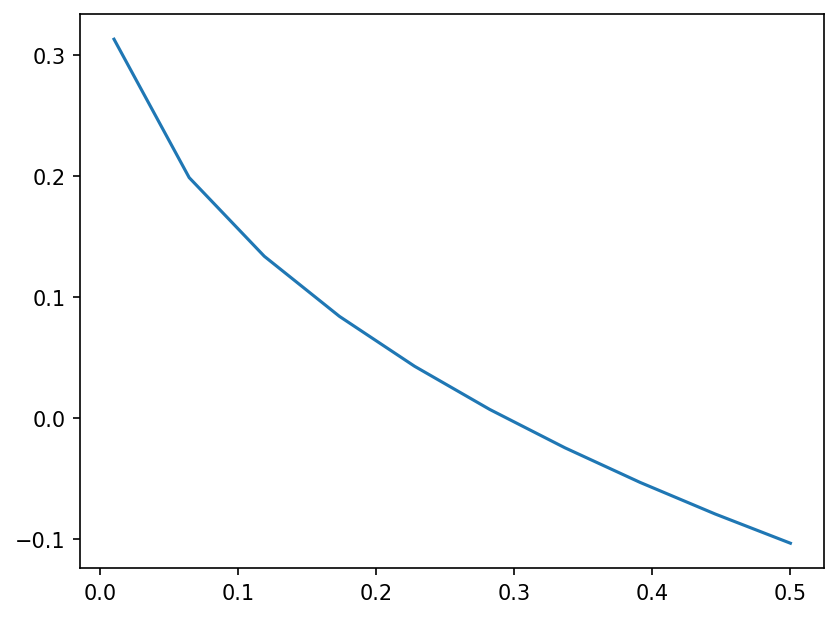

In [82]:
del_list = np.linspace(0.01*n0, 0.5*n0, 10)
diff_list = []
for i in range(10):
    aQs, aN = Get_Two_as_dens(100, 3*n0, del_list[i], 0, para.paraQMCRMF3, "PNM")
    diff_list.append(aN - aQs)

plt.plot(del_list/n0, diff_list)

In [117]:
# baryon density for interacting baryons
def _nB_test(T, muB, BI, Sigma, w0, r03, upB=5000):
    """
    Calculate baryon density for species BI, _set_couplings() should be called beforehand.

    Parameters:
    T     : temperature (MeV)
    muB   : baryon chemical potential (MeV)
    BI    : baryon index
    Sigma : scalar mean field
    w0    : vector mean field
    r03   : isovector mean field
    upB   : upper momentum cutoff for integration
    mB    : list or array of baryon masses
    gs    : list or array of scalar couplings
    gw    : list or array of omega couplings
    gr    : list or array of rho couplings
    I3    : list or array of isospin values
    """

    # Effective mass and chemical potential
    m_eff = mB[BI] - gs[BI] * Sigma
    mu_eff = muB - gw[BI] * w0 - gr[BI] * I3[BI] * r03

    # T <= 0: zero-temperature limit
    if T <= 0.0:
        if mu_eff > m_eff:
            kF = np.sqrt(np.maximum(mu_eff**2 - m_eff**2, 0.0))
            return kF**3 / (3.0 * np.pi**2)
        else:
            return 0.0

    # Sommerfeld (low-T, degenerate) approximation
    if mu_eff > m_eff:
        kF0 = np.sqrt(np.maximum(mu_eff**2 - m_eff**2, 0.0))
        n0 = kF0**3 / (3.0 * np.pi**2)
        fp = (2.0*mu_eff**2 - m_eff**2) / (np.pi**2 * np.maximum(kF0, 1e-300))
        n_low = n0 + (np.pi**2/6.0) * (T**2) * fp
    else:
        n_low = 0.0

    # Exact finite-T integral with safety clamping
    def integrand(k):
        E_star = np.sqrt(k*k + m_eff*m_eff)
        term1 = k*k / (1.0 + np.exp(np.clip((E_star - mu_eff)/T, -700.0, 700.0)))
        term2 = k*k / (1.0 + np.exp(np.clip((E_star + mu_eff)/T, -700.0, 700.0)))
        return term1 - term2

    ub = np.inf if (upB is None or np.isinf(upB)) else float(upB)
    integral, _ = quad(integrand, 0.0, ub, limit=100, epsabs=1e-8, epsrel=1e-6)
    n_int = integral / (np.pi**2)

    # Smooth logistic blend (overflow-safe)
    tiny = 1e-12
    delta = (mu_eff - m_eff) / max(T, tiny)
    x = np.clip(delta - 8.0, -700.0, 700.0)
    w_deg = 1.0 / (1.0 + np.exp(x))
    y = np.clip(-(T - 0.2)*8.0/0.2, -700.0, 700.0)
    w_T  = 1.0 / (1.0 + np.exp(y))
    w = 1.0 - (1.0 - w_deg)*(1.0 - w_T)
    w = float(np.clip(w, 0.0, 1.0))

    return (1.0 - w)*n_low + w*n_int

Max ABS diff: 2.653933e-06 at T=0.098739 MeV
Max REL diff: 1.729925e-06 at T=0.098739 MeV
At T_abs-max: n_old=1.534132e+00, n_new=1.534135e+00


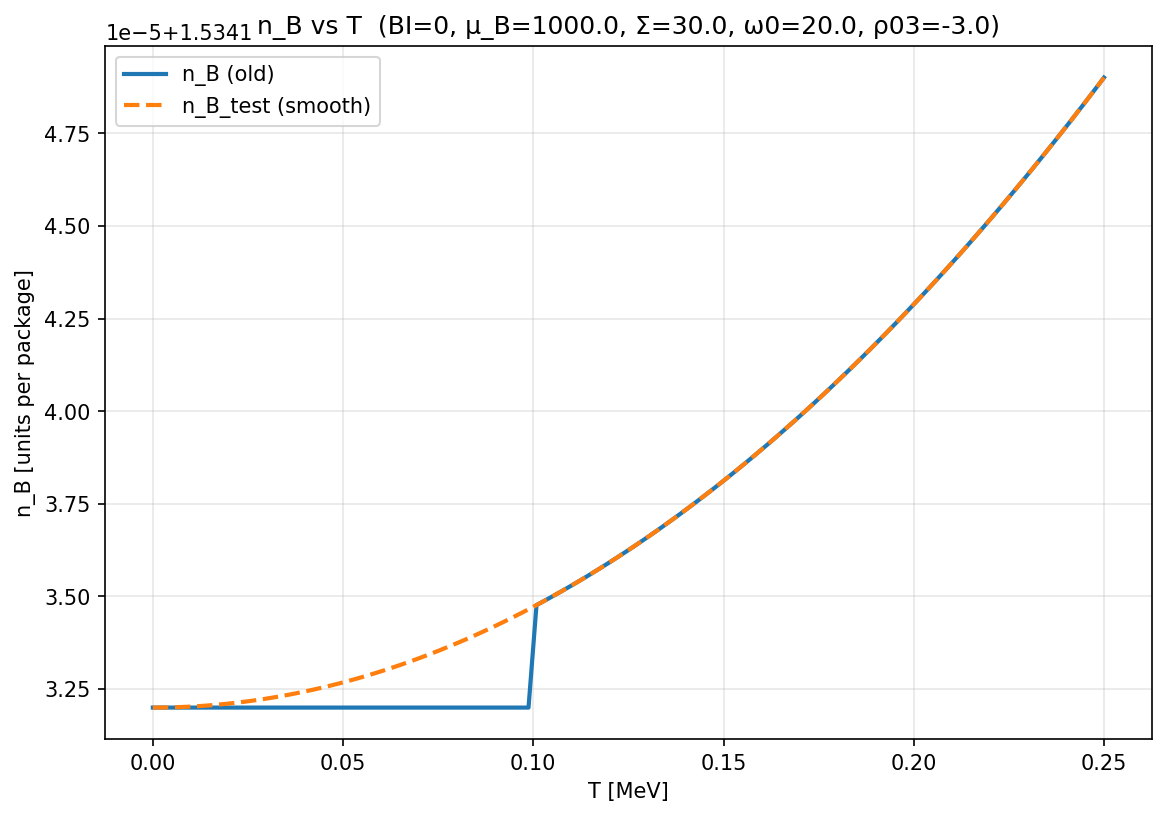

In [128]:
# --- Params you can tweak ---
BI_choice    = 0            # 0: proton, 1: neutron
muB_choice   = 1000.0       # MeV
Sigma_choice = 30.0         # MeV
w0_choice    = 20.0         # MeV
r03_choice   = -3.0         # MeV
upB_choice   = float('inf') # or 5000.0

# --- Imports ---
import numpy as np
import matplotlib.pyplot as plt

from RMFsolver.Solver import _nB as _nB_old, _set_couplings
import RMFsolver.RMFparameter as para

# IMPORTANT: load couplings first
_set_couplings(para.paraQMCRMF3)

# Pull the global arrays into this scope so _nB_test (defined in your notebook) can see them
from RMFsolver.Solver import mB, gs, gw, gr, I3  # <-- this fixes NameError in _nB_test

# Sanity check (optional):
# print("Loaded arrays:", len(mB), len(gs), len(gw), len(gr), len(I3))

# --- Temperature grid (dense near blend region around ~0.2 MeV) ---
T_low  = np.linspace(1e-5, 0.25, 120)
T_high = np.linspace(0.25, 1.0, 120)
TT = np.linspace(0, 0.25, 120)#np.unique(np.concatenate([T_low, T_high]))

# --- Compute ---
n_old = np.empty_like(TT)
n_new = np.empty_like(TT)

for i, T in enumerate(TT):
    # old (package) version
    try:
        n_old[i] = _nB_old(T, muB_choice, BI_choice, Sigma_choice, w0_choice, r03_choice, upB=upB_choice)/n0
    except TypeError:
        # if older _nB signature lacks upB
        n_old[i] = _nB_old(T, muB_choice, BI_choice, Sigma_choice, w0_choice, r03_choice)/n0

    # new smooth version (defined in this notebook as _nB_test)
    n_new[i] = _nB_test(T, muB_choice, BI_choice, Sigma_choice, w0_choice, r03_choice, upB=upB_choice)/n0

# --- Differences ---
abs_diff = np.abs(n_new - n_old)
denom    = np.maximum(1e-30, np.abs(n_old))
rel_diff = abs_diff / denom

imax_abs = int(np.argmax(abs_diff))
imax_rel = int(np.argmax(rel_diff))
print(f"Max ABS diff: {abs_diff[imax_abs]:.6e} at T={TT[imax_abs]:.6f} MeV")
print(f"Max REL diff: {rel_diff[imax_rel]:.6e} at T={TT[imax_rel]:.6f} MeV")
print(f"At T_abs-max: n_old={n_old[imax_abs]:.6e}, n_new={n_new[imax_abs]:.6e}")

# --- Plots ---
plt.figure(figsize=(9,6))
plt.plot(TT, n_old, label="n_B (old)", lw=2)
plt.plot(TT, n_new, label="n_B_test (smooth)", lw=2, ls="--")
plt.xlabel("T [MeV]"); plt.ylabel("n_B [units per package]")
plt.title(f"n_B vs T  (BI={BI_choice}, μ_B={muB_choice}, Σ={Sigma_choice}, ω0={w0_choice}, ρ03={r03_choice})")
plt.legend(); plt.grid(True, alpha=0.3); plt.show()

In [129]:
# scalar density 
def _ns_test(T, muB, BI, sigma, w0, r03, upB=5000):
    """
    Calculate baryon scalar density (source term for sigma meson).

    Parameters:
    T     : temperature (MeV)
    muB   : baryon chemical potential (MeV)
    BI    : baryon index (int)
    sigma : scalar field
    w0    : vector field
    r03   : isovector field
    mB, gs, gw, gr, I3 : model parameter arrays
    upB   : upper bound for momentum integration (default 5000 MeV)

    Returns:
    float : baryon scalar density
    """

    # ---- effective quantities (use same safety conventions as old code) ----
    m_eff = mB[BI] - gs[BI] * sigma
    mu_eff = muB - gw[BI] * w0 - gr[BI] * I3[BI] * r03

    # ---- exact T=0 branch (keep original formula + guards) ----
    if T <= 0.0:
        if mu_eff <= m_eff:
            return 0.0
        kF = np.sqrt(np.maximum(mu_eff**2 - m_eff**2, 0.0))
        term1 = m_eff * kF * mu_eff
        term2 = m_eff**3 * np.log(np.clip((mu_eff + kF) / np.maximum(m_eff, 1e-300), 1e-300, np.inf))
        return (term1 - term2) / (2 * np.pi**2)

    # ---- Sommerfeld low-T approximation (degenerate) ----
    if mu_eff > m_eff:
        kF0 = np.sqrt(np.maximum(mu_eff**2 - m_eff**2, 0.0))
        term1_0 = m_eff * kF0 * mu_eff
        term2_0 = m_eff**3 * np.log(np.clip((mu_eff + kF0) / np.maximum(m_eff, 1e-300), 1e-300, np.inf))
        ns0 = (term1_0 - term2_0) / (2.0 * np.pi**2)
        # g_s'(μ) = m_eff * μ_eff / (π^2 * kF)  =>  T^2 correction = (π^2/6) T^2 g_s'(μ)
        ns_low = ns0 + (T*T/6.0) * (m_eff * mu_eff / np.maximum(kF0, 1e-300))
    else:
        ns_low = 0.0

    # ---- exact finite-T integral (includes particles + antiparticles) ----
    def integrand(k):
        Ek = np.sqrt(k*k + m_eff*m_eff)
        f   = 1.0 / (1.0 + np.exp(np.clip((Ek - mu_eff) / T, -700.0, 700.0)))
        fbar= 1.0 / (1.0 + np.exp(np.clip((Ek + mu_eff) / T, -700.0, 700.0)))
        # scalar-density integrand: (m_eff / Ek) * k^2 * (f + fbar)
        return (m_eff / np.maximum(Ek, 1e-300)) * k*k * (f + fbar)

    ub = np.inf if (upB is None or np.isinf(upB)) else float(upB)
    integral, _ = quad(integrand, 0.0, ub, epsabs=1e-10, epsrel=1e-8, limit=200)
    ns_int = integral / (np.pi**2)

    # ---- smooth logistic blend (overflow-safe, same shape as before) ----
    tiny = 1e-12
    delta = (mu_eff - m_eff) / max(T, tiny)
    x = np.clip(delta - 8.0, -700.0, 700.0)
    w_deg = 1.0 / (1.0 + np.exp(x))                  # ~0 when highly degenerate
    y = np.clip(-(T - 0.2)*8.0/0.2, -700.0, 700.0)   # ~0 when T << 0.2
    w_T  = 1.0 / (1.0 + np.exp(y))
    w = 1.0 - (1.0 - w_deg)*(1.0 - w_T)
    w = float(np.clip(w, 0.0, 1.0))

    return (1.0 - w)*ns_low + w*ns_int

Max ABS diff: 2.310233e+00 at T = 0.098739 MeV
Max REL diff: 1.330756e-06 at T = 0.098739 MeV
At T_abs-max: ns_old = 1.736030e+06, ns_new = 1.736033e+06


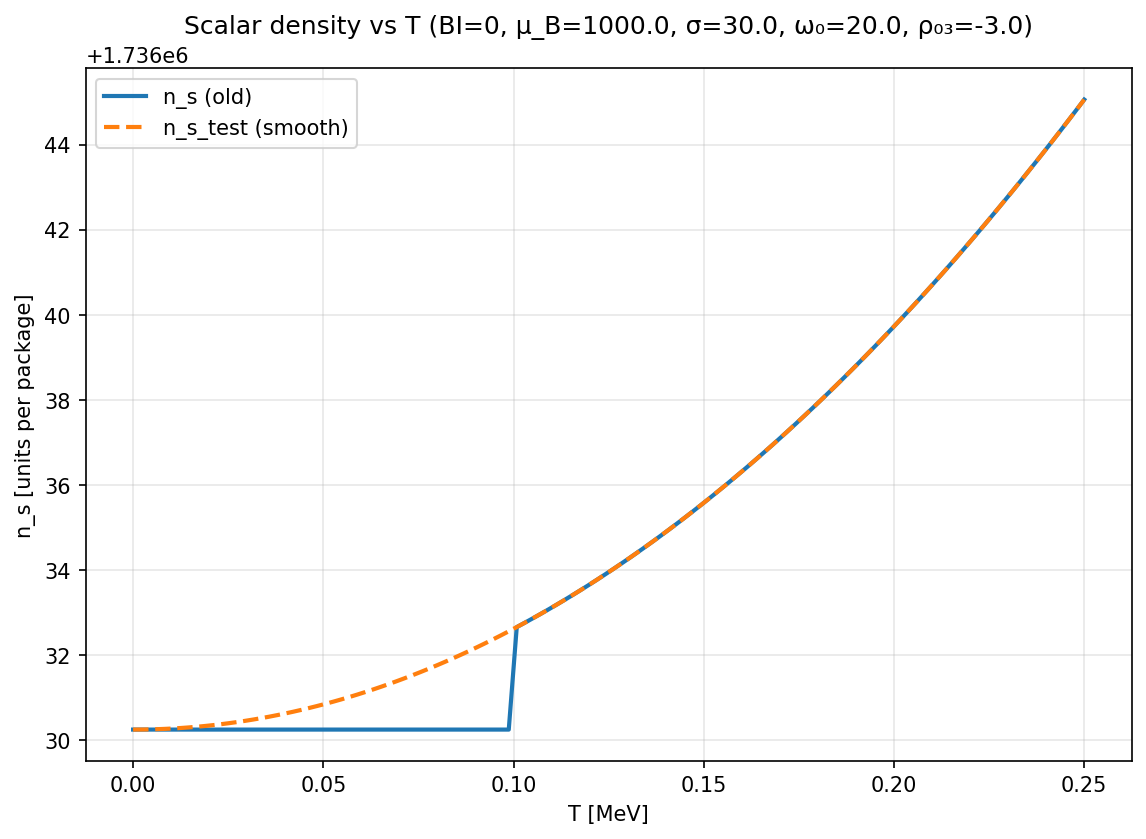

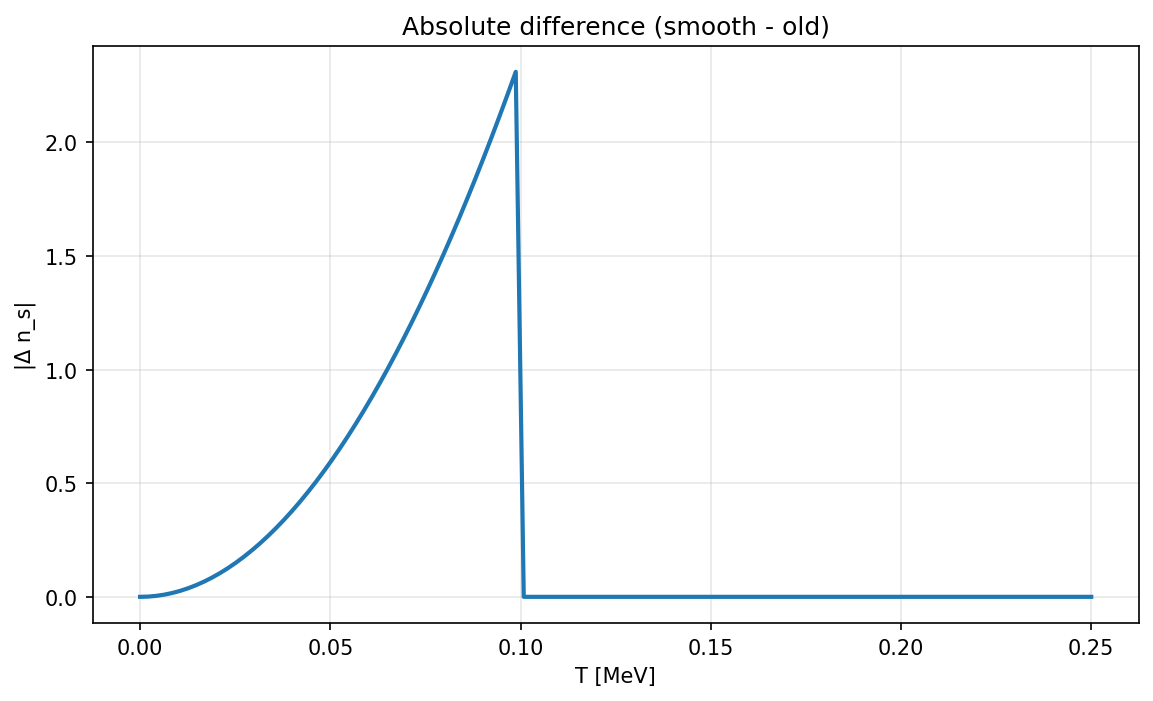

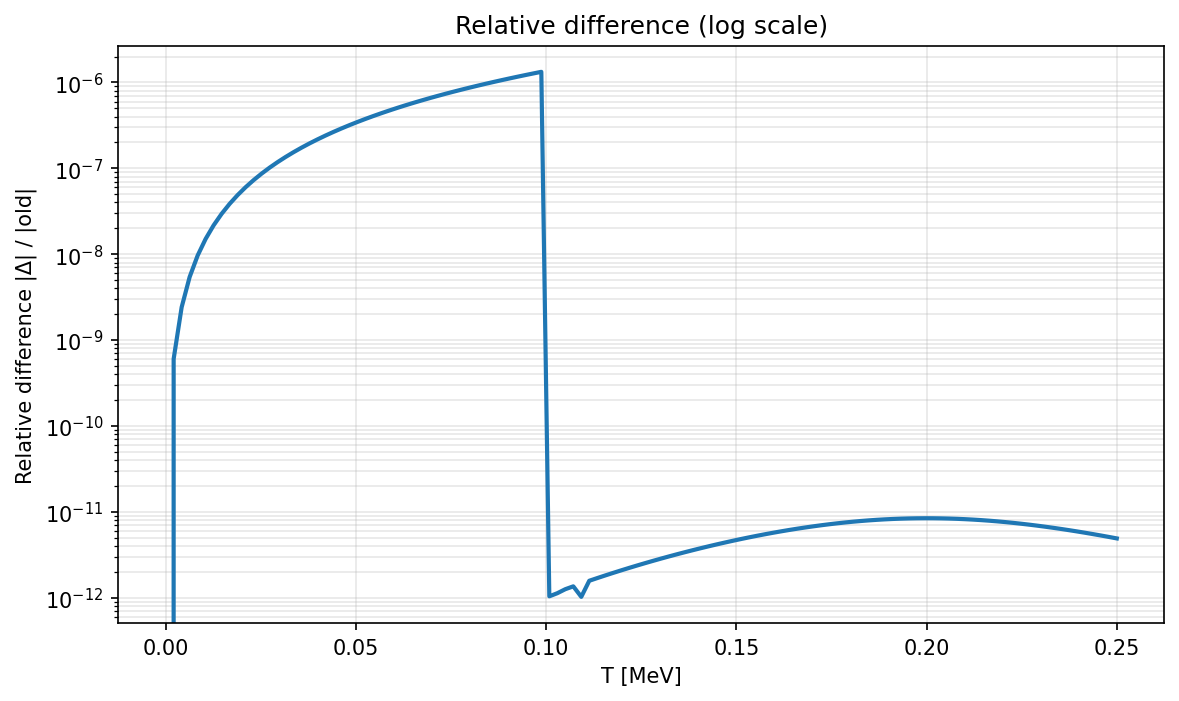

In [131]:
# --- Configuration ---
BI_choice    = 0            # 0: proton, 1: neutron
muB_choice   = 1000.0       # MeV
sigma_choice = 30.0         # MeV
w0_choice    = 20.0         # MeV
r03_choice   = -3.0         # MeV
upB_choice   = float('inf') # or 5000.0

# --- Imports ---
import numpy as np
import matplotlib.pyplot as plt

from RMFsolver.Solver import _ns as _ns_old, _set_couplings
import RMFsolver.RMFparameter as para

# initialize couplings
_set_couplings(para.paraQMCRMF3)

# expose the global arrays so _ns_test can access them
from RMFsolver.Solver import mB, gs, gw, gr, I3

# --- Temperature grid (dense near blending region ~0.2 MeV) ---
T_low  = np.linspace(1e-4, 0.25, 120)
T_high = np.linspace(0.25, 30.0, 120)
TT = np.linspace(0, 0.25, 120) #np.unique(np.concatenate([T_low, T_high]))

# --- Compute both versions ---
ns_old = np.empty_like(TT)
ns_new = np.empty_like(TT)

for i, T in enumerate(TT):
    try:
        ns_old[i] = _ns_old(T, muB_choice, BI_choice, sigma_choice, w0_choice, r03_choice, upB=upB_choice)
    except TypeError:
        ns_old[i] = _ns_old(T, muB_choice, BI_choice, sigma_choice, w0_choice, r03_choice)
    ns_new[i] = _ns_test(T, muB_choice, BI_choice, sigma_choice, w0_choice, r03_choice, upB=upB_choice)

# --- Compute differences ---
abs_diff = np.abs(ns_new - ns_old)
denom = np.maximum(1e-30, np.abs(ns_old))
rel_diff = abs_diff / denom

imax_abs = int(np.argmax(abs_diff))
imax_rel = int(np.argmax(rel_diff))
print(f"Max ABS diff: {abs_diff[imax_abs]:.6e} at T = {TT[imax_abs]:.6f} MeV")
print(f"Max REL diff: {rel_diff[imax_rel]:.6e} at T = {TT[imax_rel]:.6f} MeV")
print(f"At T_abs-max: ns_old = {ns_old[imax_abs]:.6e}, ns_new = {ns_new[imax_abs]:.6e}")

# --- Plots ---
plt.figure(figsize=(9,6))
plt.plot(TT, ns_old, label="n_s (old)", lw=2)
plt.plot(TT, ns_new, label="n_s_test (smooth)", lw=2, ls="--")
plt.xlabel("T [MeV]")
plt.ylabel("n_s [units per package]")
plt.title(f"Scalar density vs T (BI={BI_choice}, μ_B={muB_choice}, σ={sigma_choice}, ω₀={w0_choice}, ρ₀₃={r03_choice})")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(9,5))
plt.plot(TT, abs_diff, lw=2)
plt.xlabel("T [MeV]")
plt.ylabel("|Δ n_s|")
plt.title("Absolute difference (smooth - old)")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(9,5))
plt.plot(TT, rel_diff, lw=2)
plt.xlabel("T [MeV]")
plt.ylabel("Relative difference |Δ| / |old|")
plt.title("Relative difference (log scale)")
plt.yscale("log")
plt.grid(True, which="both", alpha=0.3)
plt.show()

In [132]:
# electron contributions
# electrons=free fermion density, needs setcouplings
def n_electron_test(T, muQ, me=0.511, upB=5000):
    """
    Electron number density assuming a free Fermi gas.

    Parameters:
    T    : temperature (MeV)
    muQ  : charge chemical potential (MeV)
    me   : electron mass (MeV), default 0.511
    upB  : upper bound for integration (MeV)

    Returns:
    float : electron number density (1/fm^3)
    """
    from scipy.integrate import quad
    import numpy as np

    T = float(T); muQ = float(muQ); me = float(me)
    # T <= 0 branch
    if T <= 0.0:
        if muQ > me:
            kF0 = np.sqrt(np.maximum(muQ*muQ - me*me, 0.0))
            return kF0**3 / (3.0 * np.pi**2)
        else:
            return 0.0

    # Sommerfeld low-T approximation
    if muQ > me:
        kF0 = np.sqrt(np.maximum(muQ*muQ - me*me, 0.0))
        n0 = kF0**3 / (3.0 * np.pi**2)
        fp = (2.0*muQ*muQ - me*me) / (np.pi**2 * np.maximum(kF0, 1e-300))
        n_low = n0 + (np.pi**2/6.0) * (T*T) * fp
    else:
        n_low = 0.0

    # Exact finite-T integral (particles - antiparticles)
    def integrand(k):
        Ek = np.sqrt(k*k + me*me)
        f    = 1.0 / (1.0 + np.exp(np.clip((Ek - muQ)/T, -700.0, 700.0)))
        fbar = 1.0 / (1.0 + np.exp(np.clip((Ek + muQ)/T, -700.0, 700.0)))
        return (f - fbar) * k*k

    ub = np.inf if (upB is None or np.isinf(upB)) else float(upB)
    integral, _ = quad(integrand, 0.0, ub, epsabs=1e-10, epsrel=1e-8, limit=200)
    n_int = integral / (np.pi**2)

    # Smooth logistic blend (overflow-safe)
    tiny = 1e-12
    delta = (muQ - me) / max(T, tiny)
    x = np.clip(delta - 8.0, -700.0, 700.0)
    w_deg = 1.0 / (1.0 + np.exp(x))
    y = np.clip(-(T - 0.2)*8.0/0.2, -700.0, 700.0)
    w_T  = 1.0 / (1.0 + np.exp(y))
    w = 1.0 - (1.0 - w_deg)*(1.0 - w_T)
    w = float(np.clip(w, 0.0, 1.0))

    return (1.0 - w)*n_low + w*n_int

Max ABS diff: 6.499659e-01 at T = 0.098739 MeV
Max REL diff: 2.405613e-06 at T = 0.098739 MeV
At T_abs-max: n_old = 2.701872e+05, n_new = 2.701878e+05


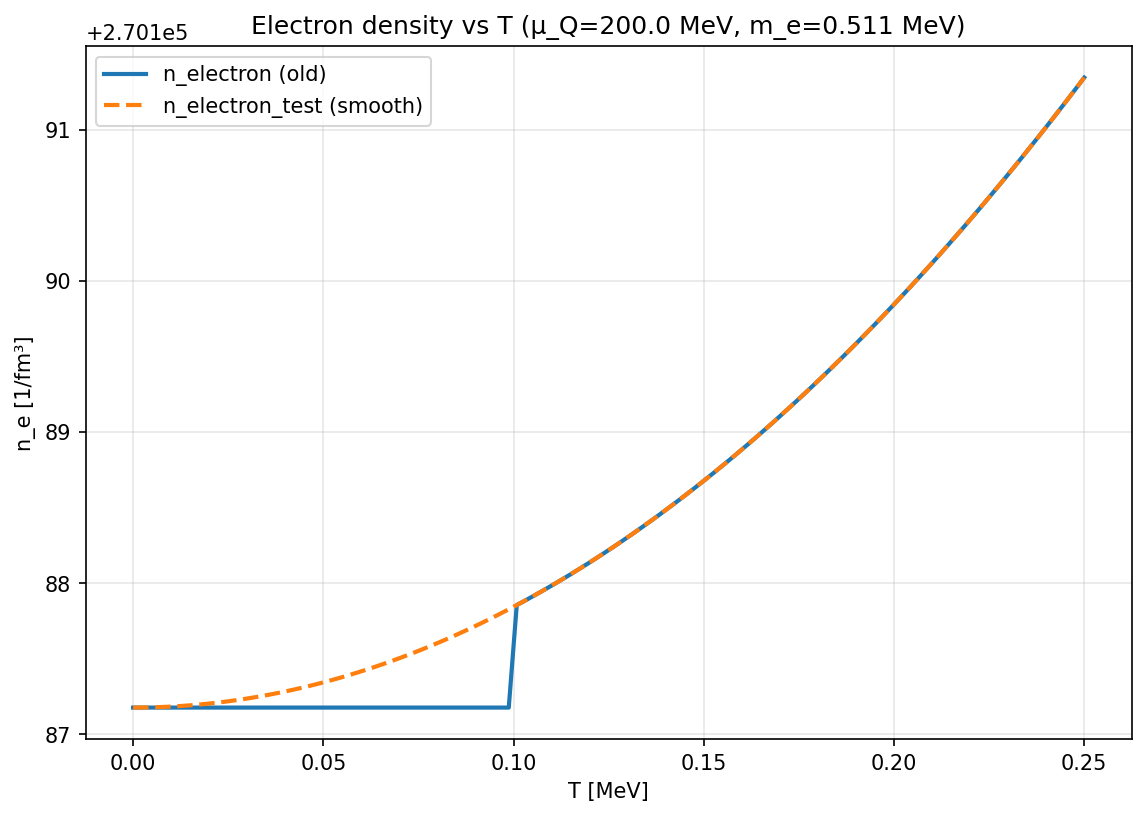

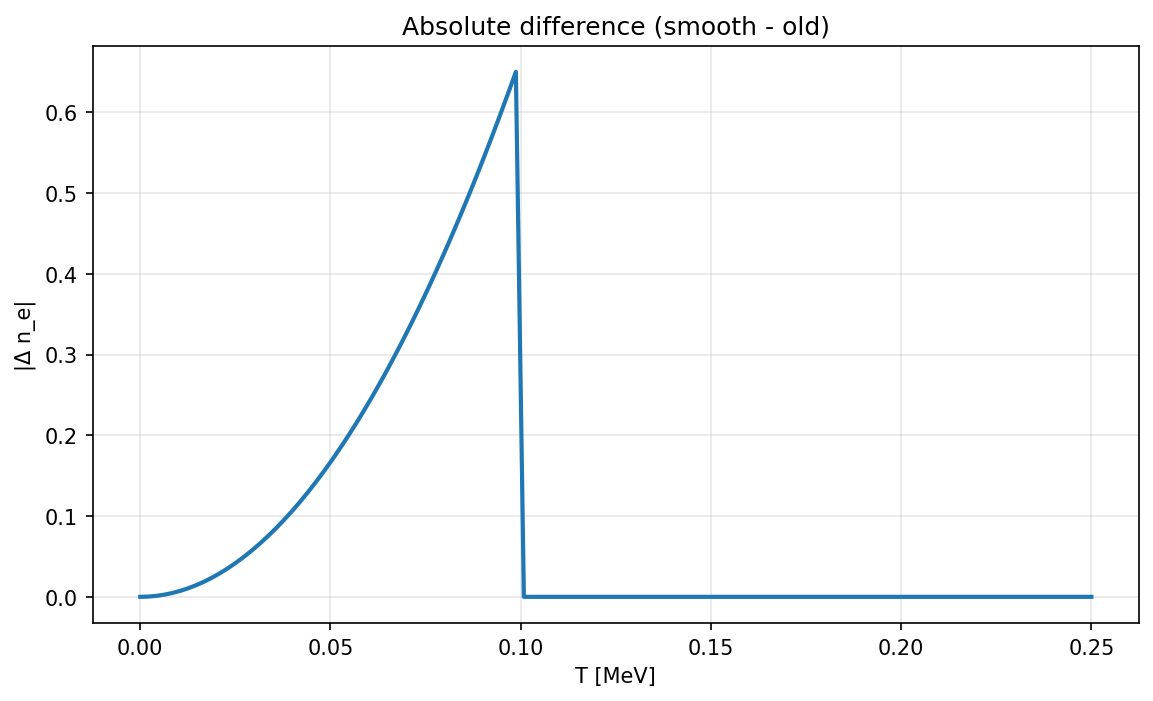

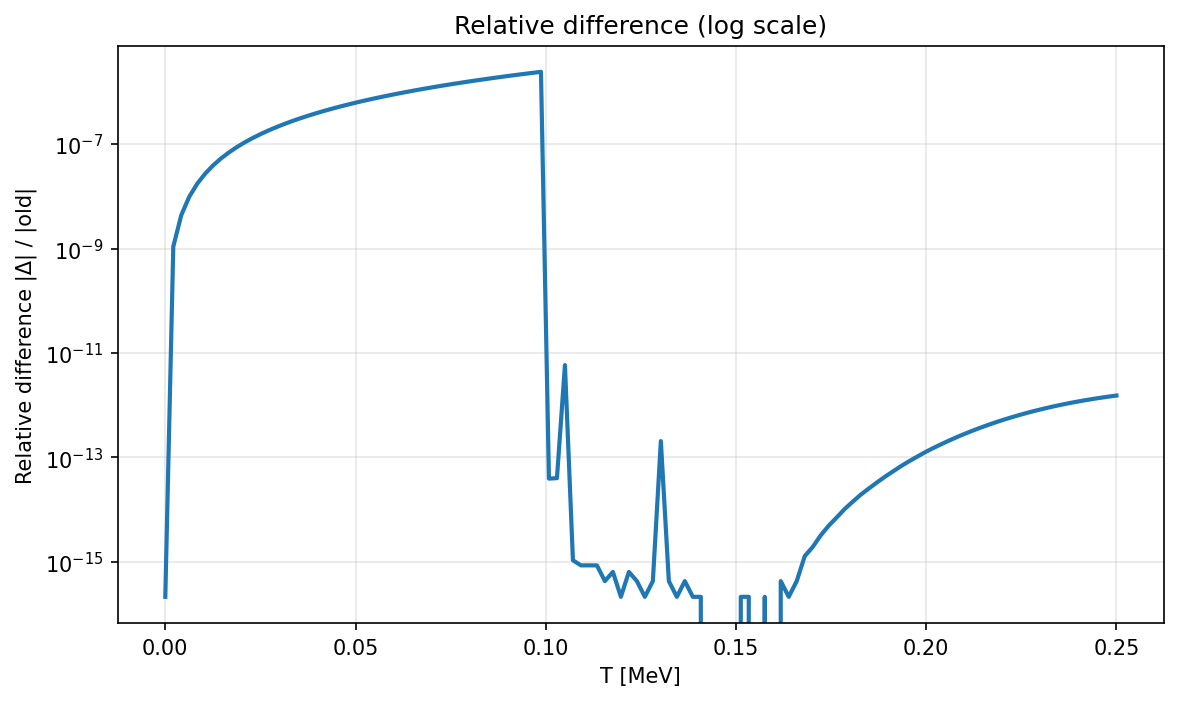

In [134]:
# --- Configuration ---
muQ_choice  = 200.0       # MeV (charge chemical potential)
me_choice   = 0.511       # MeV (electron rest mass)
upB_choice  = float('inf') # or 5000.0 for finite cutoff

# --- Imports ---
import numpy as np
import matplotlib.pyplot as plt
from RMFsolver.Solver import n_electron as n_electron_old

# new smooth version should already be defined in this notebook as n_electron_test

# --- Temperature grid (fine around 0.2 MeV where smoothing matters) ---
T_low  = np.linspace(1e-4, 0.25, 120)
T_high = np.linspace(0.25, 30.0, 120)
TT = np.linspace(0, 0.25, 120)#np.unique(np.concatenate([T_low, T_high]))

# --- Evaluate both versions ---
n_old = np.empty_like(TT)
n_new = np.empty_like(TT)

for i, T in enumerate(TT):
    try:
        n_old[i] = n_electron_old(T, muQ_choice, me_choice, upB=upB_choice)
    except TypeError:
        # if older signature didn't accept upB
        n_old[i] = n_electron_old(T, muQ_choice, me_choice)
    n_new[i] = n_electron_test(T, muQ_choice, me_choice, upB=upB_choice)

# --- Compute differences ---
abs_diff = np.abs(n_new - n_old)
denom = np.maximum(1e-30, np.abs(n_old))
rel_diff = abs_diff / denom

imax_abs = int(np.argmax(abs_diff))
imax_rel = int(np.argmax(rel_diff))
print(f"Max ABS diff: {abs_diff[imax_abs]:.6e} at T = {TT[imax_abs]:.6f} MeV")
print(f"Max REL diff: {rel_diff[imax_rel]:.6e} at T = {TT[imax_rel]:.6f} MeV")
print(f"At T_abs-max: n_old = {n_old[imax_abs]:.6e}, n_new = {n_new[imax_abs]:.6e}")

# --- Plot results ---
plt.figure(figsize=(9,6))
plt.plot(TT, n_old, label="n_electron (old)", lw=2)
plt.plot(TT, n_new, label="n_electron_test (smooth)", lw=2, ls="--")
plt.xlabel("T [MeV]")
plt.ylabel("n_e [1/fm³]")
plt.title(f"Electron density vs T (μ_Q={muQ_choice} MeV, m_e={me_choice} MeV)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(9,5))
plt.plot(TT, abs_diff, lw=2)
plt.xlabel("T [MeV]")
plt.ylabel("|Δ n_e|")
plt.title("Absolute difference (smooth - old)")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(9,5))
plt.plot(TT, rel_diff, lw=2)
plt.xlabel("T [MeV]")
plt.ylabel("Relative difference |Δ| / |old|")
plt.title("Relative difference (log scale)")
plt.yscale("log")
plt.grid(True, which="both", alpha=0.3)
plt.show()

/var/folders/zx/mchmm24s5sj4l19_jxvlkj380000gn/T/ipykernel_4962/621627158.py:20: RuntimeWarning: divide by zero encountered in scalar divide
  return k**2 / (1 + np.exp(np.clip((Ek - muQ) / T, -700, 700)))
/var/folders/zx/mchmm24s5sj4l19_jxvlkj380000gn/T/ipykernel_4962/621627158.py:24: RuntimeWarning: divide by zero encountered in scalar divide
  return k**2 / (1 + np.exp(np.clip((Ek + muQ) / T, -700, 700)))


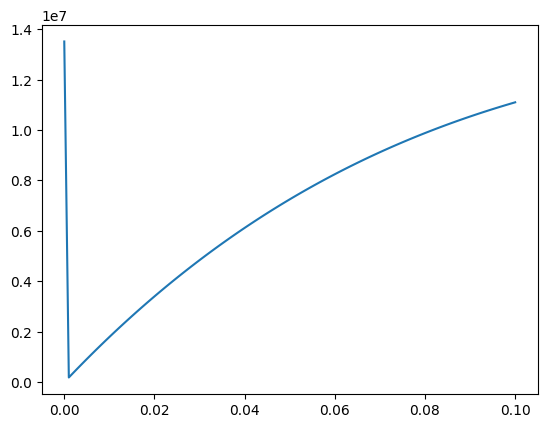

In [20]:
from RMFsolver.Solver import n_electron
import matplotlib.pyplot as plt

TT = np.linspace(0, 0.1, 100)
nn = np.array([n_electron_old(TT[i], 200) for i in range(100)])
PP = np.array([electron_pressure_old(TT[i], 200) for i in range(100)])

plt.plot(TT, PP)

In [19]:
from scipy.integrate import quad
import numpy as np

def n_electron_old(T, muQ, me=0.511, upB=5000):
    """
    Electron number density assuming a free Fermi gas.

    Parameters:
    T    : temperature (MeV)
    muQ  : charge chemical potential (MeV)
    me   : electron mass (MeV), default 0.511
    upB  : upper bound for integration (MeV)

    Returns:
    float : electron number density (1/fm^3)
    """
    if T >= 0:
        def integrand_f(k):
            Ek = np.sqrt(k**2 + me**2)
            return k**2 / (1 + np.exp(np.clip((Ek - muQ) / T, -700, 700)))

        def integrand_fbar(k):
            Ek = np.sqrt(k**2 + me**2)
            return k**2 / (1 + np.exp(np.clip((Ek + muQ) / T, -700, 700)))

        f_int, _ = quad(integrand_f, 0, upB, epsabs=1e-10, epsrel=1e-8)
        fbar_int, _ = quad(integrand_fbar, 0, upB, epsabs=1e-10, epsrel=1e-8)
        return (f_int - fbar_int) / np.pi**2

    else:
        if muQ > me:
            return ((muQ**2 - me**2)**1.5) / (3 * np.pi**2)
        else:
            return 0.0

def electron_pressure_old(T, muQ, me=0.511, upB=5000):
    """
    Free electron pressure at finite or zero temperature.

    Parameters:
    T    : temperature (MeV)
    muQ  : charge chemical potential
    me   : electron mass (MeV)
    upB  : upper bound for integration (MeV)

    Returns:
    float : pressure (MeV^4)
    """
    if T <= 1e-3:
        return (2 / 3) * muQ**4 / (8 * np.pi**2)

    def integrand(k):
        Ek = np.sqrt(k**2 + me**2)
        arg1 = np.clip(-(Ek - muQ) / T, -700, 700)
        arg2 = np.clip(-(Ek + muQ) / T, -700, 700)
        return 2 * T * k**2 * (np.log(1 + np.exp(arg1)) + np.log(1 + np.exp(arg2))) / (2 * np.pi**2)

    result, _ = quad(integrand, 0, upB, epsabs=1e-10, epsrel=1e-8)
    return result

In [135]:
def electron_pressure_test(T, muQ, me=0.511, upB=5000):
    """
    Free electron pressure at finite or zero temperature.

    Parameters:
    T    : temperature (MeV)
    muQ  : charge chemical potential
    me   : electron mass (MeV)
    upB  : upper bound for integration (MeV)

    Returns:
    float : pressure (MeV^4)
    """
    import numpy as np
    from scipy.integrate import quad

    # cast to floats
    T   = float(T)
    muQ = float(muQ)
    me  = float(me)

    # ---------- zero-T branch ----------
    # P0(μ, m): exact T=0 pressure (massless limit included)
    if T <= 0.0:
        if muQ <= me:
            return 0.0
        if me == 0.0:
            return muQ**4 / (12.0*np.pi**2)
        kF = np.sqrt(np.maximum(muQ*muQ - me*me, 0.0))
        return ((2.0*kF**3 - 3.0*me*me*kF)*muQ + 3.0*me**4*np.log((kF+muQ)/np.maximum(me,1e-300))) / (24.0*np.pi**2)

    # ---------- Sommerfeld low-T correction (degenerate) ----------
    if muQ > me:
        kF0 = np.sqrt(np.maximum(muQ*muQ - me*me, 0.0))
        if me == 0.0:
            P0  = muQ**4 / (12.0*np.pi**2)
            fmu = muQ*muQ / (np.pi**2)                 # f(μ)
        else:
            P0  = ((2.0*kF0**3 - 3.0*me*me*kF0)*muQ + 3.0*me**4*np.log((kF0+muQ)/np.maximum(me,1e-300))) / (24.0*np.pi**2)
            fmu = (muQ * kF0) / (np.pi**2)             # f(μ) = μ √(μ²-m²)/π²
        P_low = P0 + (np.pi**2/6.0) * (T*T) * fmu
    else:
        P_low = 0.0

    # ---------- exact finite-T integral (particles + antiparticles) ----------
    def integrand(k):
        Ek = np.sqrt(k*k + me*me)
        a  = np.clip((Ek - muQ)/T, -700.0, 700.0)
        b  = np.clip((Ek + muQ)/T, -700.0, 700.0)
        # use log1p for stability
        arg  = T*np.log1p(np.exp(-a))
        argb = T*np.log1p(np.exp(-b))
        return (arg + argb) * k*k

    ub = np.inf if (upB is None or np.isinf(upB)) else float(upB)
    Pint, _ = quad(integrand, 0.0, ub, epsabs=1e-10, epsrel=1e-8, limit=200)
    P_int = Pint / (np.pi**2)

    # ---------- smooth logistic blend (overflow-safe) ----------
    tiny = 1e-12
    delta = (muQ - me) / max(T, tiny)  # degeneracy measure
    x = np.clip(delta - 8.0, -700.0, 700.0)
    w_deg = 1.0 / (1.0 + np.exp(x))               # ~0 when highly degenerate
    y = np.clip(-(T - 0.2)*8.0/0.2, -700.0, 700.0)  # ~0 when T << 0.2 MeV
    w_T  = 1.0 / (1.0 + np.exp(y))
    w = 1.0 - (1.0 - w_deg)*(1.0 - w_T)
    w = float(np.clip(w, 0.0, 1.0))

    return (1.0 - w)*P_low + w*P_int

Max ABS diff: 1.198302e+07 at T = 0.008403 MeV
Max REL diff: 7.880540e+00 at T = 0.008403 MeV
At T_abs-max: P_old = 1.520583e+06, P_new = 1.350360e+07


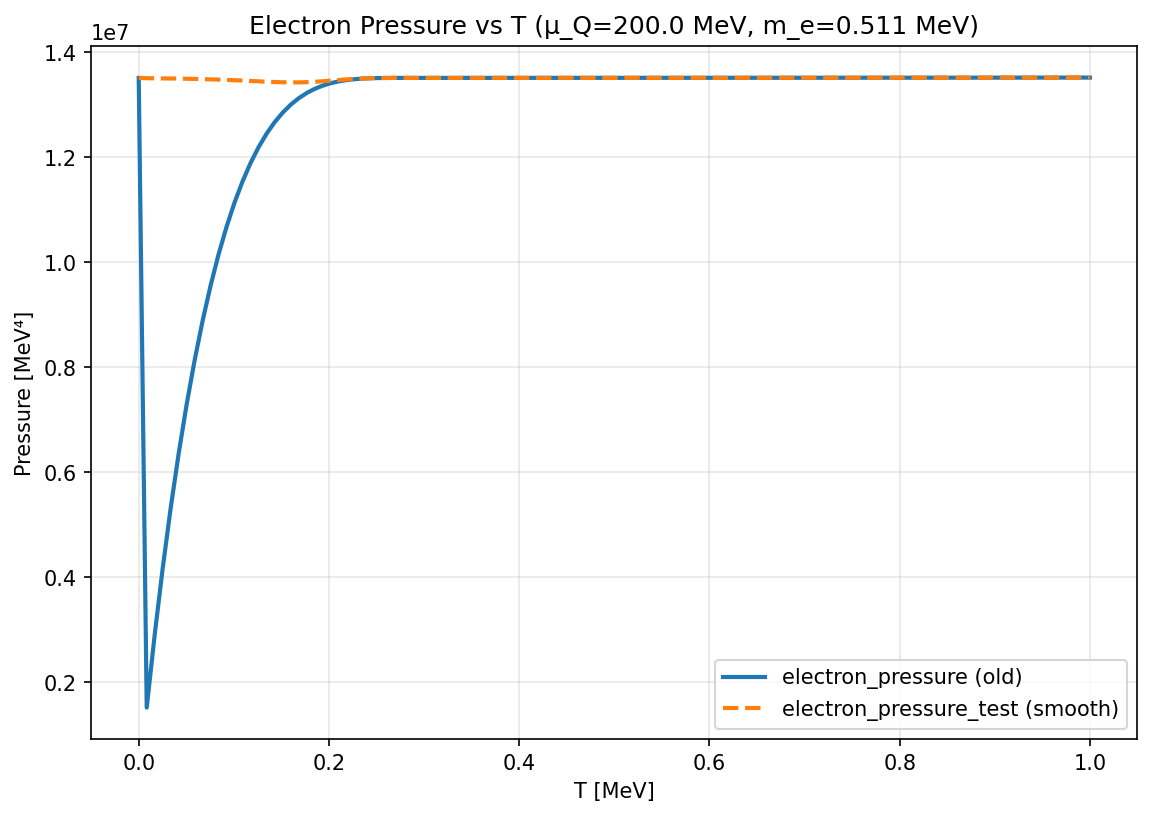

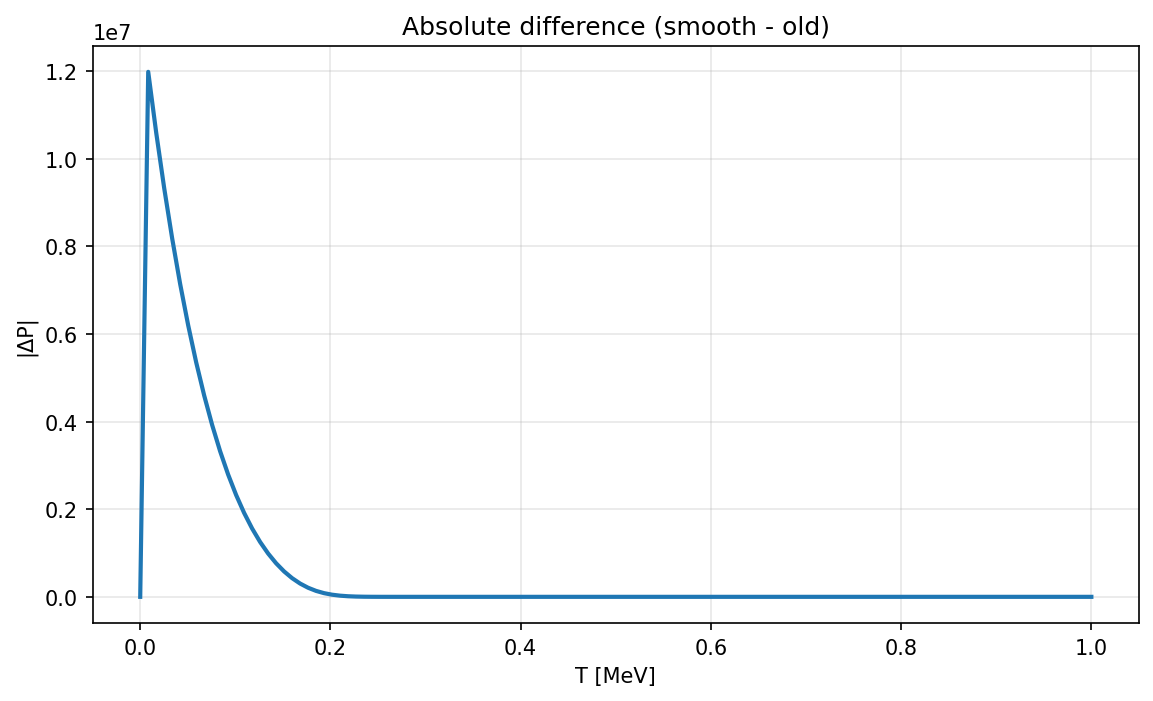

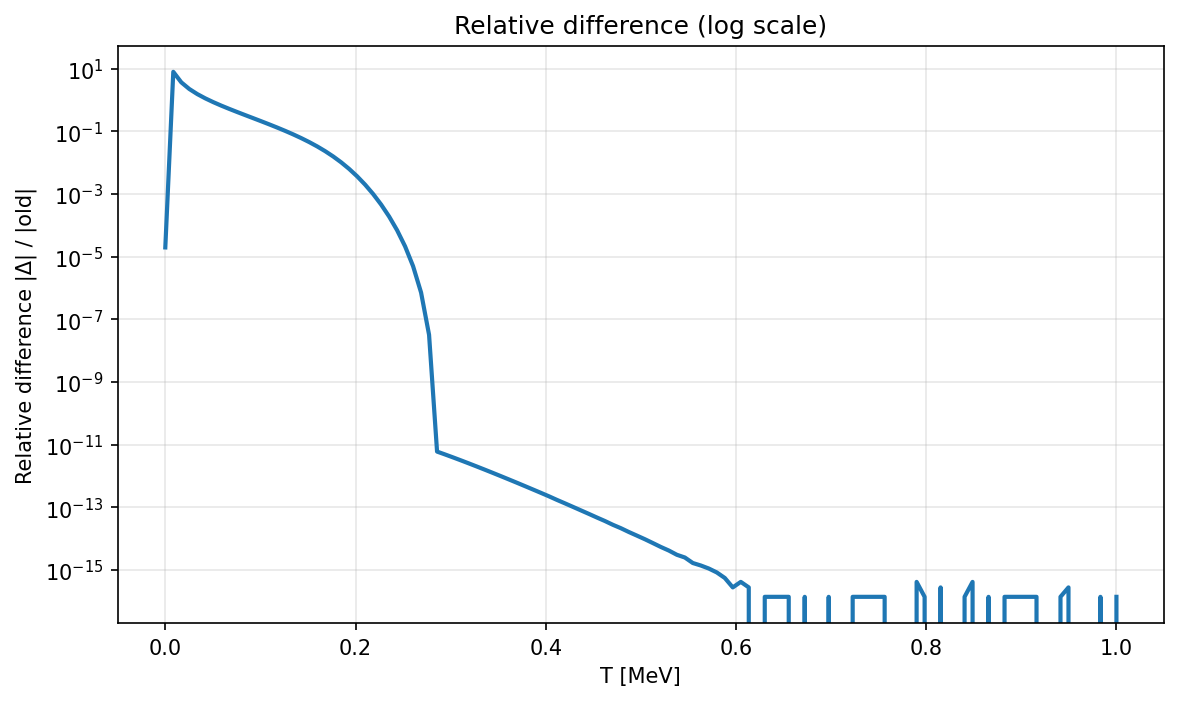

In [138]:
# --- Configuration ---
muQ_choice = 200.0        # MeV (charge chemical potential)
me_choice  = 0.511        # MeV (electron rest mass)
upB_choice = float('inf') # or 5000.0 to test finite cutoff behavior

# --- Imports ---
import numpy as np
import matplotlib.pyplot as plt
from RMFsolver.Solver import electron_pressure as electron_pressure_old

# new smooth version should already be defined as electron_pressure_test in your notebook

# --- Temperature grid (dense near ~0.2 MeV) ---
T_low  = np.linspace(1e-4, 0.25, 120)
T_high = np.linspace(0.25, 30.0, 120)
TT = np.linspace(0, 1, 120) #np.unique(np.concatenate([T_low, T_high]))

# --- Evaluate both versions ---
P_old = np.empty_like(TT)
P_new = np.empty_like(TT)

for i, T in enumerate(TT):
    try:
        P_old[i] = electron_pressure_old(T, muQ_choice, me_choice, upB=upB_choice)
    except TypeError:
        # In case the old function didn't take upB
        P_old[i] = electron_pressure_old(T, muQ_choice, me_choice)
    P_new[i] = electron_pressure_test(T, muQ_choice, me_choice, upB=upB_choice)

# --- Compute differences ---
abs_diff = np.abs(P_new - P_old)
denom = np.maximum(1e-30, np.abs(P_old))
rel_diff = abs_diff / denom

imax_abs = int(np.argmax(abs_diff))
imax_rel = int(np.argmax(rel_diff))
print(f"Max ABS diff: {abs_diff[imax_abs]:.6e} at T = {TT[imax_abs]:.6f} MeV")
print(f"Max REL diff: {rel_diff[imax_rel]:.6e} at T = {TT[imax_rel]:.6f} MeV")
print(f"At T_abs-max: P_old = {P_old[imax_abs]:.6e}, P_new = {P_new[imax_abs]:.6e}")

# --- Plot results ---
plt.figure(figsize=(9,6))
plt.plot(TT, P_old, label="electron_pressure (old)", lw=2)
plt.plot(TT, P_new, label="electron_pressure_test (smooth)", lw=2, ls="--")
plt.xlabel("T [MeV]")
plt.ylabel("Pressure [MeV⁴]")
plt.title(f"Electron Pressure vs T (μ_Q={muQ_choice} MeV, m_e={me_choice} MeV)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(9,5))
plt.plot(TT, abs_diff, lw=2)
plt.xlabel("T [MeV]")
plt.ylabel("|ΔP|")
plt.title("Absolute difference (smooth - old)")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(9,5))
plt.plot(TT, rel_diff, lw=2)
plt.xlabel("T [MeV]")
plt.ylabel("Relative difference |Δ| / |old|")
plt.title("Relative difference (log scale)")
plt.yscale("log")
plt.grid(True, which="both", alpha=0.3)
plt.show()

In [139]:
# neutrino contributions
def n_neutrino_test(T, mu_nu, up=4000):
    """
    Neutrino number density.

    Parameters:
    T      : temperature (MeV)
    mu_nu  : neutrino chemical potential (MeV)
    up     : integration upper limit (MeV)

    Returns:
    float : neutrino number density
    """
    import numpy as np
    from scipy.integrate import quad

    T = float(T); mu_nu = float(mu_nu)

    # ---- exact T=0 limit (massless, one helicity) ----
    if T <= 0.0:
        # n0 = μ^3 / (6 π^2) for massless neutrinos (g=1), anti-ν handled by μ→-μ
        mu_abs = abs(mu_nu)
        return (mu_abs**3) / (6.0 * np.pi**2)

    # ---- Sommerfeld low-T approximation (massless, g=1) ----
    # n_low = μ^3/(6π^2) + (π^2/6) T^2 * f'(μ),
    # with f(E) = E^2/(2π^2)  =>  f'(μ) = μ/π^2  => correction = (1/6) μ T^2
    mu_abs = abs(mu_nu)
    n0 = (mu_abs**3) / (6.0 * np.pi**2)
    n_low = n0 + (mu_abs * T*T) / 6.0

    # ---- exact finite-T integral (particles − antiparticles) ----
    def integrand(k):
        # E = k for massless neutrinos
        a = np.clip((k - mu_nu)/T, -700.0, 700.0)
        b = np.clip((k + mu_nu)/T, -700.0, 700.0)
        f    = 1.0/(1.0 + np.exp(a))
        fbar = 1.0/(1.0 + np.exp(b))
        return (f - fbar) * k*k

    ub = np.inf if (up is None or np.isinf(up)) else float(up)
    integral, _ = quad(integrand, 0.0, ub, epsabs=1e-10, epsrel=1e-8, limit=200)
    n_int = integral / (2.0 * np.pi**2)

    # ---- smooth logistic blend (overflow-safe) ----
    # degeneracy measure uses m=0 -> delta = |μ|/T
    tiny = 1e-12
    delta = mu_abs / max(T, tiny)
    x = np.clip(delta - 8.0, -700.0, 700.0)
    w_deg = 1.0 / (1.0 + np.exp(x))                 # ~0 when highly degenerate (prefer Sommerfeld)
    y = np.clip(-(T - 0.2)*8.0/0.2, -700.0, 700.0)  # ~0 when T << 0.2
    w_T  = 1.0 / (1.0 + np.exp(y))
    w = 1.0 - (1.0 - w_deg)*(1.0 - w_T)
    w = float(np.clip(w, 0.0, 1.0))

    return (1.0 - w)*n_low + w*n_int

Max ABS diff: 3.249829e-01 at T = 0.098739 MeV
Max REL diff: 2.405590e-06 at T = 0.098739 MeV
At T_abs-max: n_old = 1.350949e+05, n_new = 1.350952e+05


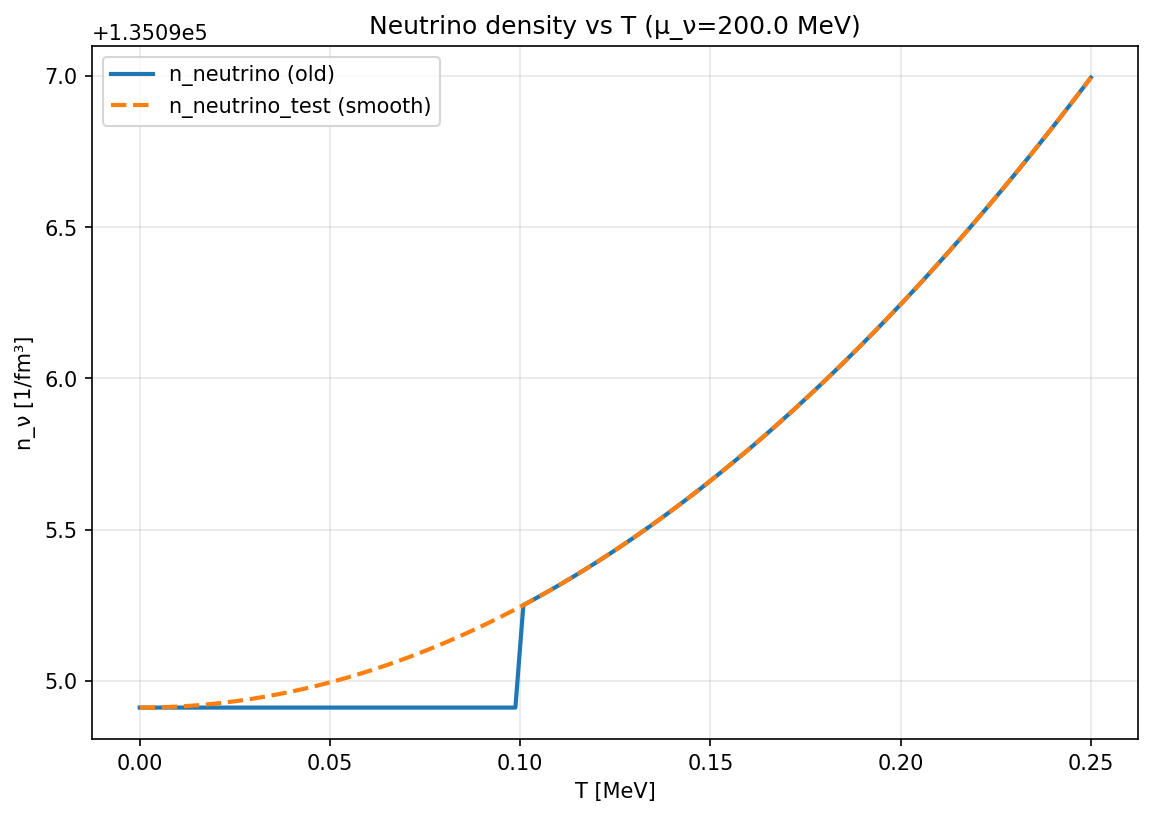

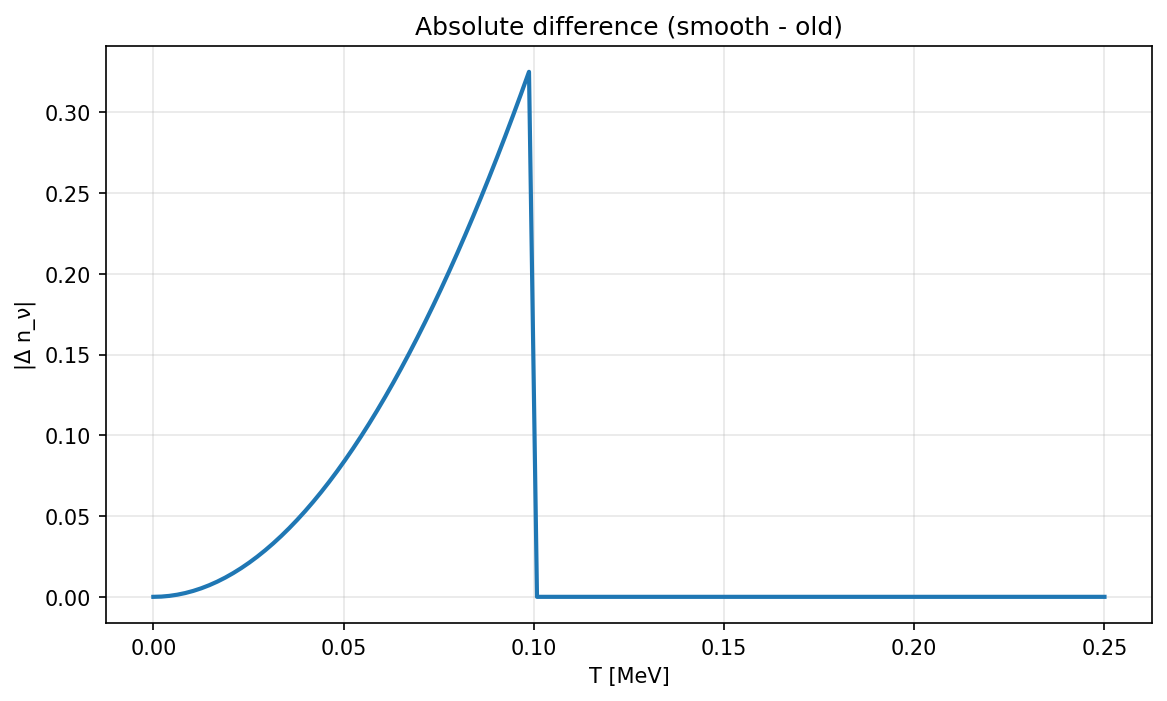

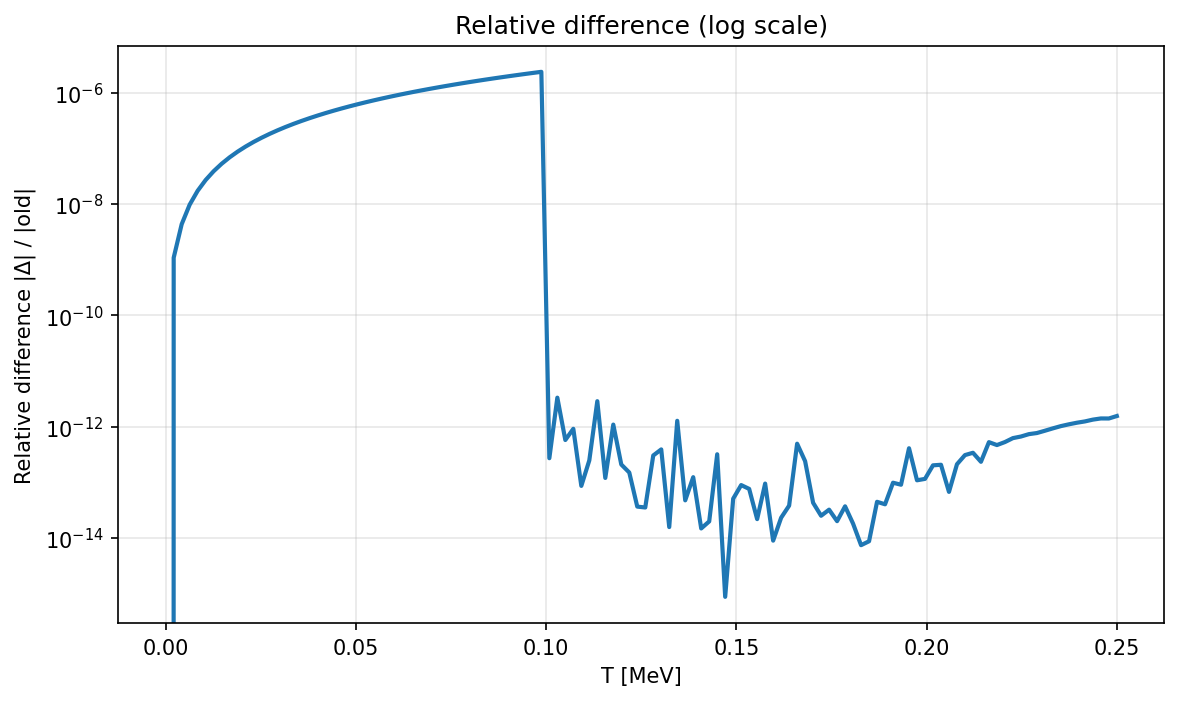

In [141]:
# --- Configuration ---
mu_nu_choice = 200.0       # MeV (neutrino chemical potential)
up_choice    = float('inf')  # or 4000.0 for finite upper bound

# --- Imports ---
import numpy as np
import matplotlib.pyplot as plt
from RMFsolver.Solver import n_neutrino as n_neutrino_old

# new smoothed version should already be defined as n_neutrino_test in this notebook

# --- Temperature grid ---
T_low  = np.linspace(1e-4, 0.25, 120)
T_high = np.linspace(0.25, 30.0, 120)
TT = np.linspace(0, 0.25, 120) #np.unique(np.concatenate([T_low, T_high]))

# --- Evaluate both versions ---
n_old = np.empty_like(TT)
n_new = np.empty_like(TT)

for i, T in enumerate(TT):
    try:
        n_old[i] = n_neutrino_old(T, mu_nu_choice, up=up_choice)
    except TypeError:
        n_old[i] = n_neutrino_old(T, mu_nu_choice)
    n_new[i] = n_neutrino_test(T, mu_nu_choice, up=up_choice)

# --- Differences ---
abs_diff = np.abs(n_new - n_old)
denom = np.maximum(1e-30, np.abs(n_old))
rel_diff = abs_diff / denom

imax_abs = int(np.argmax(abs_diff))
imax_rel = int(np.argmax(rel_diff))
print(f"Max ABS diff: {abs_diff[imax_abs]:.6e} at T = {TT[imax_abs]:.6f} MeV")
print(f"Max REL diff: {rel_diff[imax_rel]:.6e} at T = {TT[imax_rel]:.6f} MeV")
print(f"At T_abs-max: n_old = {n_old[imax_abs]:.6e}, n_new = {n_new[imax_abs]:.6e}")

# --- Plots ---
plt.figure(figsize=(9,6))
plt.plot(TT, n_old, label="n_neutrino (old)", lw=2)
plt.plot(TT, n_new, label="n_neutrino_test (smooth)", lw=2, ls="--")
plt.xlabel("T [MeV]")
plt.ylabel("n_ν [1/fm³]")
plt.title(f"Neutrino density vs T (μ_ν={mu_nu_choice} MeV)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(9,5))
plt.plot(TT, abs_diff, lw=2)
plt.xlabel("T [MeV]")
plt.ylabel("|Δ n_ν|")
plt.title("Absolute difference (smooth - old)")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(9,5))
plt.plot(TT, rel_diff, lw=2)
plt.xlabel("T [MeV]")
plt.ylabel("Relative difference |Δ| / |old|")
plt.title("Relative difference (log scale)")
plt.yscale("log")
plt.grid(True, which="both", alpha=0.3)
plt.show()

In [142]:
def neutrino_pressure_test(T, mu_nu, up=4000):
    """
    Neutrino pressure (massless fermion, one helicity state).

    Parameters:
    T      : temperature (MeV)
    mu_nu  : neutrino chemical potential (MeV)
    up     : integration upper limit (MeV), default 4000

    Returns:
    float : neutrino pressure (MeV^4)
    """
    import numpy as np
    from scipy.integrate import quad

    T = float(T); mu_nu = float(mu_nu)

    # ---------- T = 0 branch ----------
    # For a massless fermion with one helicity, P = μ^4 / (24π^2)
    if T <= 0.0:
        return mu_nu**4 / (24.0 * np.pi**2)

    # ---------- Sommerfeld low-T approximation ----------
    # For massless neutrino: P_low = μ^4/(24π^2) + (μ^2 T^2)/(12) + (7π^2 T^4)/(360)
    # Derived from expansion of Fermi-Dirac integrals.
    P_low = (mu_nu**4) / (24.0 * np.pi**2) \
          + (mu_nu**2 * T*T) / 12.0 \
          + (7.0 * np.pi**2 / 360.0) * T**4

    # ---------- exact finite-T integral ----------
    def integrand(k):
        # For massless neutrinos, E = k
        a = np.clip((k - mu_nu) / T, -700.0, 700.0)
        b = np.clip((k + mu_nu) / T, -700.0, 700.0)
        arg  = T * np.log1p(np.exp(-a))
        argb = T * np.log1p(np.exp(-b))
        return (arg + argb) * k*k

    ub = np.inf if (up is None or np.isinf(up)) else float(up)
    Pint, _ = quad(integrand, 0.0, ub, epsabs=1e-10, epsrel=1e-8, limit=200)
    P_int = Pint / (2.0 * np.pi**2)

    # ---------- smooth logistic blend (overflow-safe) ----------
    tiny = 1e-12
    delta = abs(mu_nu) / max(T, tiny)
    x = np.clip(delta - 8.0, -700.0, 700.0)
    w_deg = 1.0 / (1.0 + np.exp(x))                # ~0 when highly degenerate (prefer Sommerfeld)
    y = np.clip(-(T - 0.2)*8.0/0.2, -700.0, 700.0) # ~0 when T << 0.2 MeV
    w_T  = 1.0 / (1.0 + np.exp(y))
    w = 1.0 - (1.0 - w_deg)*(1.0 - w_T)
    w = float(np.clip(w, 0.0, 1.0))

    return (1.0 - w)*P_low + w*P_int

Max ABS diff: 5.991633e+06 at T = 0.008403 MeV
Max REL diff: 7.880624e+00 at T = 0.008403 MeV
At T_abs-max: P_old = 7.602993e+05, P_new = 6.751933e+06


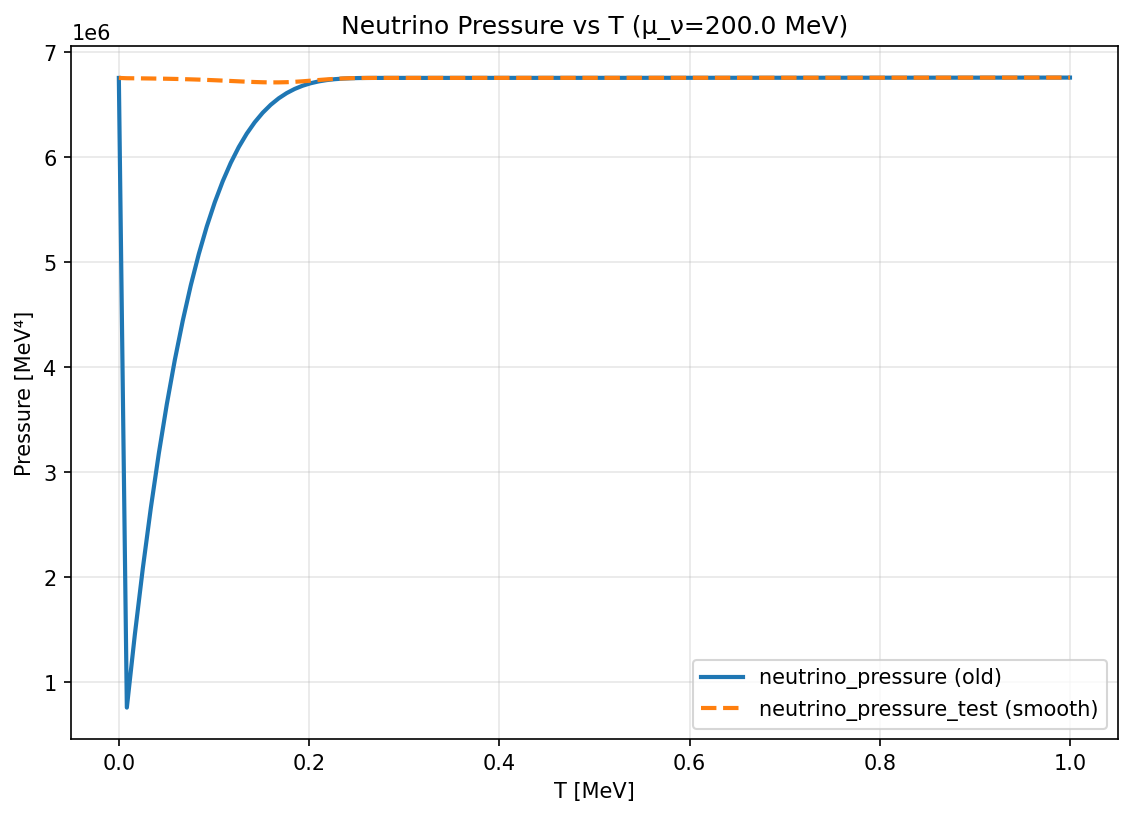

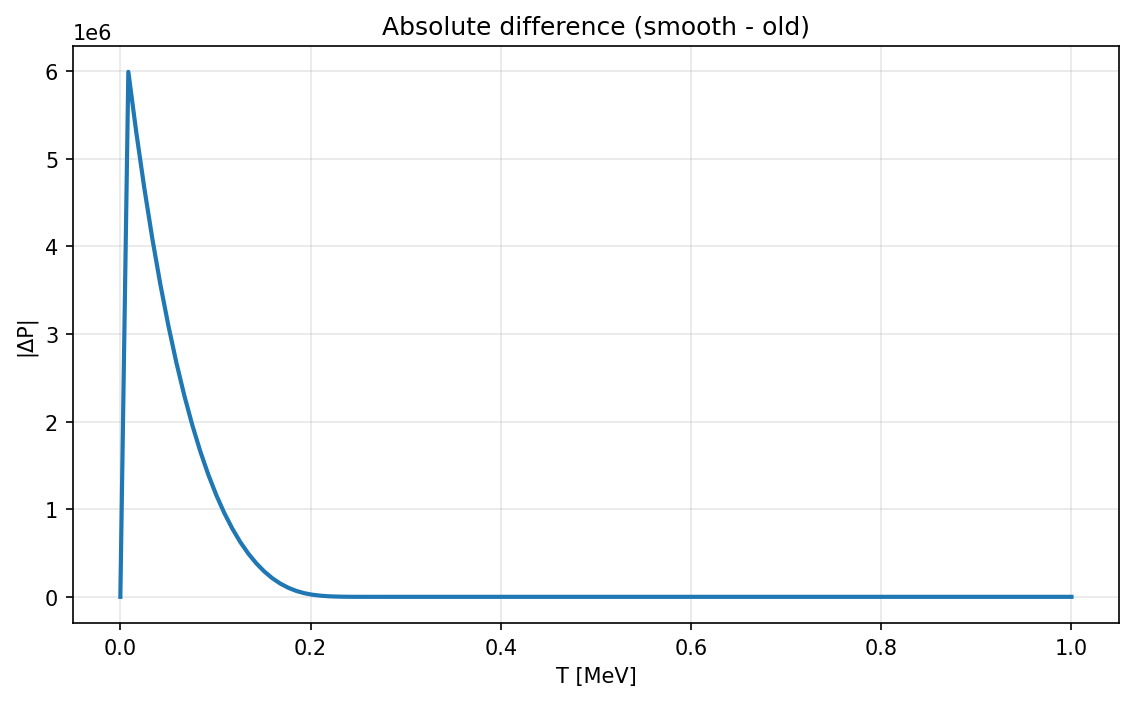

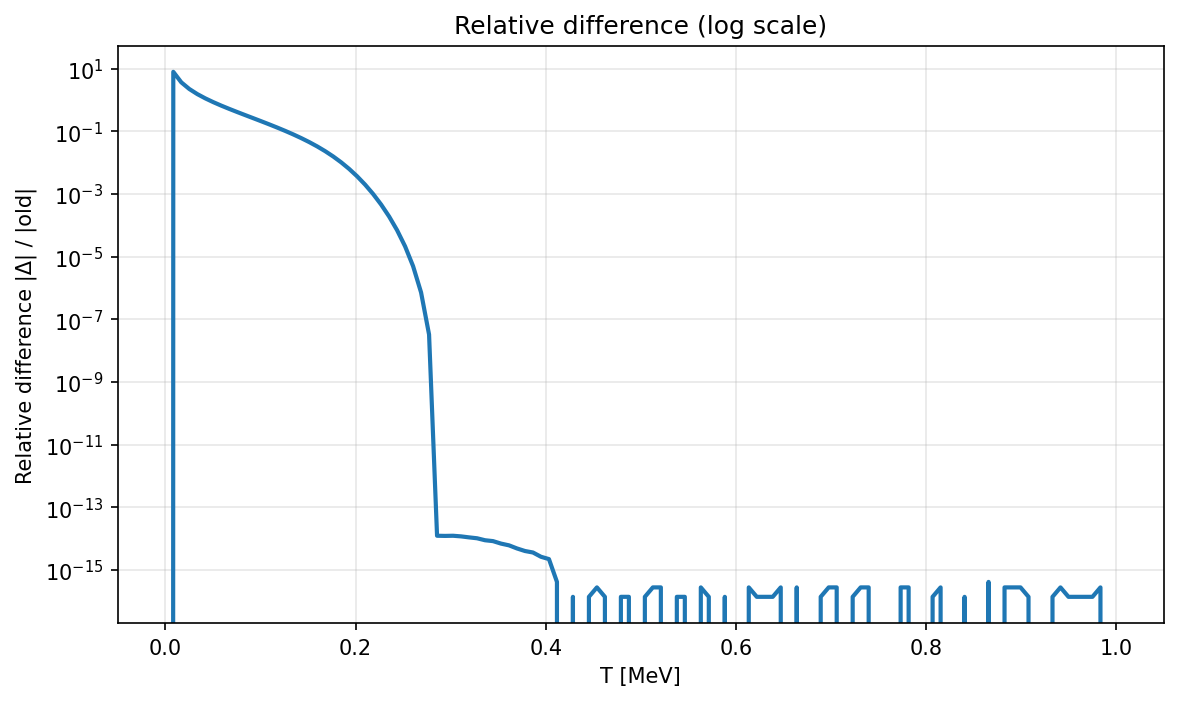

In [144]:
# --- Configuration ---
mu_nu_choice = 200.0        # MeV (neutrino chemical potential)
up_choice    = float('inf') # or 4000.0 to test finite cutoff behavior

# --- Imports ---
import numpy as np
import matplotlib.pyplot as plt
from RMFsolver.Solver import neutrino_pressure as neutrino_pressure_old
# new smooth version should already be defined in this notebook as neutrino_pressure_test

# --- Temperature grid (dense near ~0.2 MeV where blending transitions) ---
T_low  = np.linspace(1e-4, 0.25, 120)
T_high = np.linspace(0.25, 30.0, 120)
TT = np.linspace(0, 1, 120) #np.unique(np.concatenate([T_low, T_high]))

# --- Evaluate both versions ---
P_old = np.empty_like(TT)
P_new = np.empty_like(TT)

for i, T in enumerate(TT):
    try:
        P_old[i] = neutrino_pressure_old(T, mu_nu_choice, up=up_choice)
    except TypeError:
        # If older signature didn't accept 'up'
        P_old[i] = neutrino_pressure_old(T, mu_nu_choice)
    P_new[i] = neutrino_pressure_test(T, mu_nu_choice, up=up_choice)

# --- Differences ---
abs_diff = np.abs(P_new - P_old)
denom    = np.maximum(1e-30, np.abs(P_old))
rel_diff = abs_diff / denom

imax_abs = int(np.argmax(abs_diff))
imax_rel = int(np.argmax(rel_diff))
print(f"Max ABS diff: {abs_diff[imax_abs]:.6e} at T = {TT[imax_abs]:.6f} MeV")
print(f"Max REL diff: {rel_diff[imax_rel]:.6e} at T = {TT[imax_rel]:.6f} MeV")
print(f"At T_abs-max: P_old = {P_old[imax_abs]:.6e}, P_new = {P_new[imax_abs]:.6e}")

# --- Plots ---
plt.figure(figsize=(9,6))
plt.plot(TT, P_old, label="neutrino_pressure (old)", lw=2)
plt.plot(TT, P_new, label="neutrino_pressure_test (smooth)", lw=2, ls="--")
plt.xlabel("T [MeV]")
plt.ylabel("Pressure [MeV⁴]")
plt.title(f"Neutrino Pressure vs T (μ_ν={mu_nu_choice} MeV)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(9,5))
plt.plot(TT, abs_diff, lw=2)
plt.xlabel("T [MeV]")
plt.ylabel("|ΔP|")
plt.title("Absolute difference (smooth - old)")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(9,5))
plt.plot(TT, rel_diff, lw=2)
plt.xlabel("T [MeV]")
plt.ylabel("Relative difference |Δ| / |old|")
plt.title("Relative difference (log scale)")
plt.yscale("log")
plt.grid(True, which="both", alpha=0.3)
plt.show()

In [145]:
def neutrino_edens_test(T, mu_nu, up=4000):
    """
    Neutrino energy density (massless fermion, one helicity state).

    Parameters:
    T      : temperature (MeV)
    mu_nu  : neutrino chemical potential (MeV)
    up     : integration upper limit (MeV), default 4000

    Returns:
    float : energy density (MeV^4)
    """
    import numpy as np
    from scipy.integrate import quad

    T = float(T)
    mu_nu = float(mu_nu)

    # ---------- zero-T limit ----------
    # For massless fermion (g = 1 helicity): ε₀ = μ⁴ / (8π²)
    if T <= 0.0:
        return mu_nu**4 / (8.0 * np.pi**2)

    # ---------- Sommerfeld low-T expansion ----------
    # For massless neutrino: ε_low = μ⁴/(8π²) + μ²T²/4 + 7π²T⁴/120
    e_low = (mu_nu**4) / (8.0 * np.pi**2) \
          + (mu_nu**2 * T*T) / 4.0 \
          + (7.0 * np.pi**2 / 120.0) * T**4

    # ---------- exact finite-T integral ----------
    def integrand(k):
        a = np.clip((k - mu_nu) / T, -700.0, 700.0)
        b = np.clip((k + mu_nu) / T, -700.0, 700.0)
        f   = 1.0 / (1.0 + np.exp(a))
        fbar= 1.0 / (1.0 + np.exp(b))
        return (f + fbar) * k**3

    ub = np.inf if (up is None or np.isinf(up)) else float(up)
    eint, _ = quad(integrand, 0.0, ub, epsabs=1e-10, epsrel=1e-8, limit=200)
    e_int = eint / (2.0 * np.pi**2)

    # ---------- smooth logistic blending ----------
    tiny = 1e-12
    delta = abs(mu_nu) / max(T, tiny)               # degeneracy measure
    x = np.clip(delta - 8.0, -700.0, 700.0)
    w_deg = 1.0 / (1.0 + np.exp(x))                 # ~0 when highly degenerate
    y = np.clip(-(T - 0.2)*8.0/0.2, -700.0, 700.0)  # ~0 when T << 0.2 MeV
    w_T  = 1.0 / (1.0 + np.exp(y))
    w = 1.0 - (1.0 - w_deg)*(1.0 - w_T)
    w = float(np.clip(w, 0.0, 1.0))

    return (1.0 - w)*e_low + w*e_int

Max ABS diff: 9.339035e+01 at T = 0.096639 MeV
Max REL diff: 4.608629e-06 at T = 0.096639 MeV
At T_abs-max: E_old = 2.026424e+07, E_new = 2.026433e+07


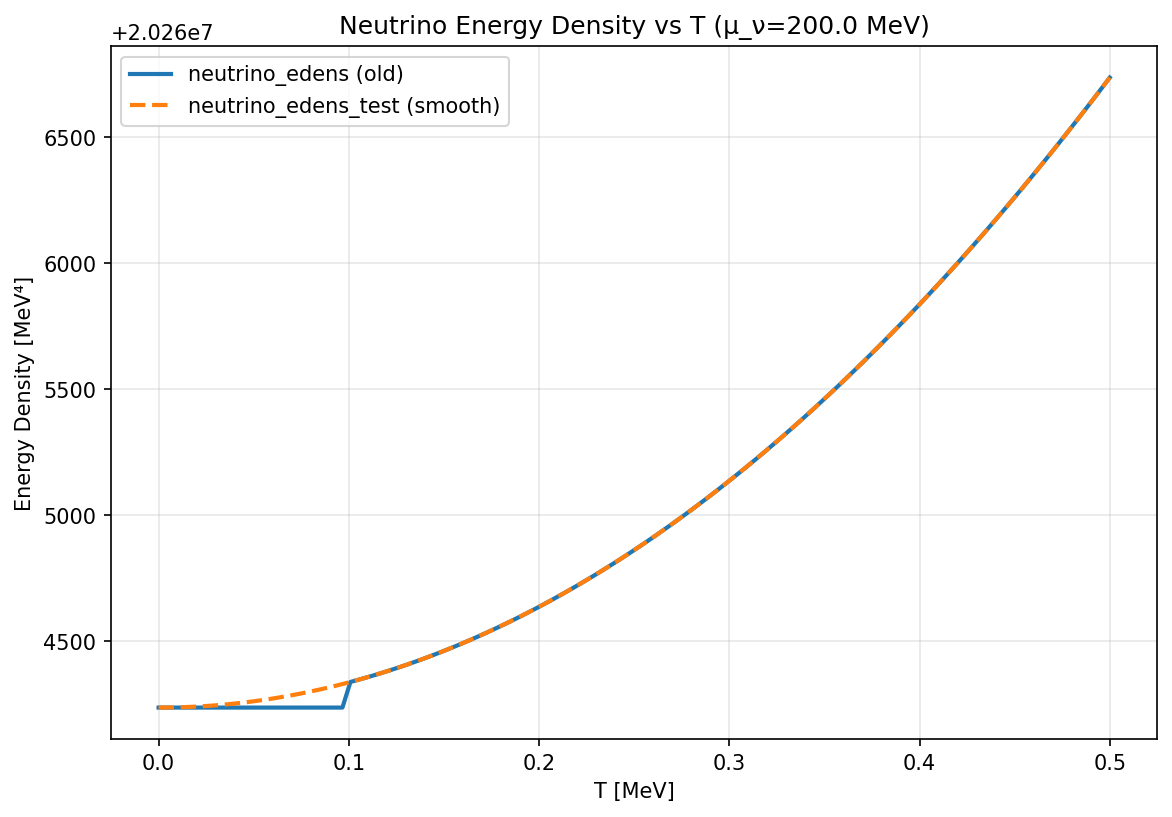

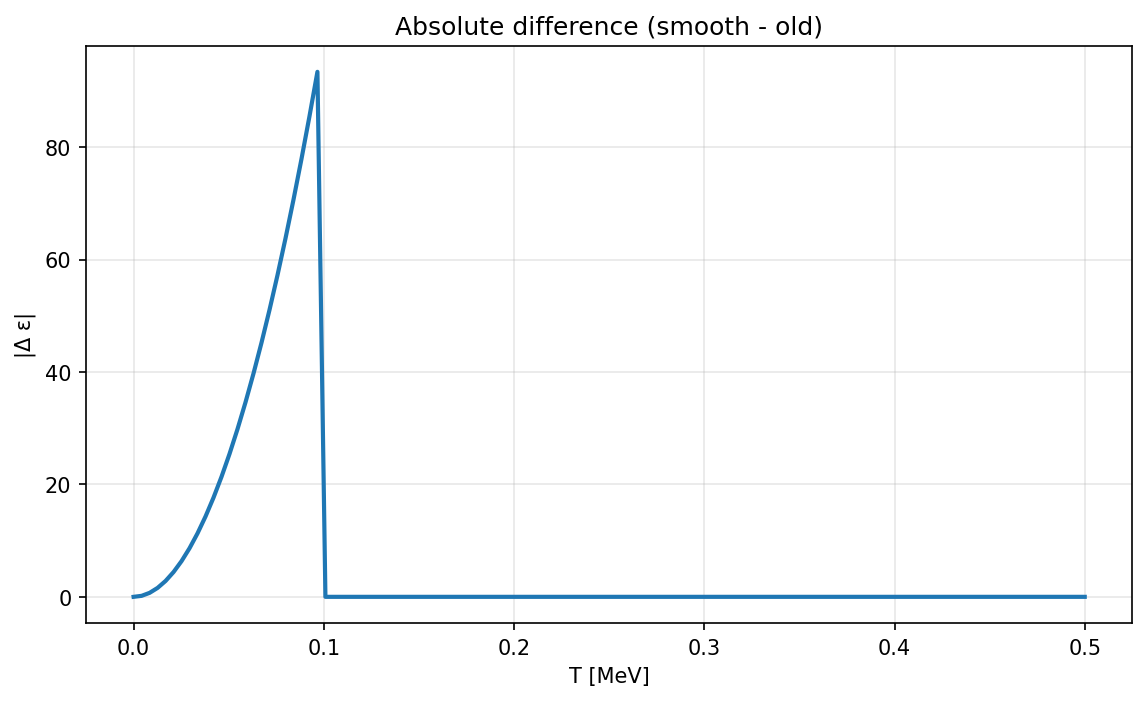

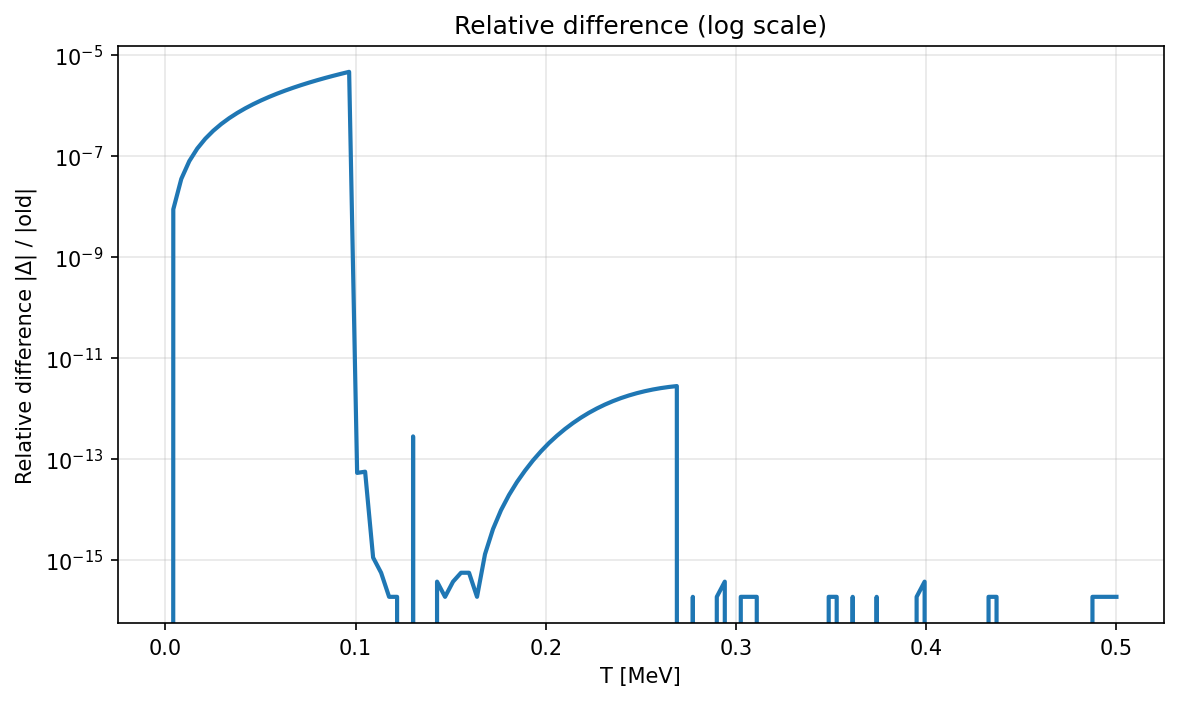

In [147]:
# --- Configuration ---
mu_nu_choice = 200.0        # MeV (neutrino chemical potential)
up_choice    = float('inf') # or 4000.0 to match the legacy function

# --- Imports ---
import numpy as np
import matplotlib.pyplot as plt
from RMFsolver.Solver import neutrino_edens as neutrino_edens_old

# new smooth version should already be defined in this notebook as neutrino_edens_test

# --- Temperature grid (uniform) ---
TT = np.linspace(0.0, 0.5, 120)

# --- Evaluate both versions ---
E_old = np.empty_like(TT)
E_new = np.empty_like(TT)

for i, T in enumerate(TT):
    try:
        E_old[i] = neutrino_edens_old(T, mu_nu_choice, up=up_choice)
    except TypeError:
        # In case the old signature doesn't take 'up'
        E_old[i] = neutrino_edens_old(T, mu_nu_choice)
    E_new[i] = neutrino_edens_test(T, mu_nu_choice, up=up_choice)

# --- Compute differences ---
abs_diff = np.abs(E_new - E_old)
denom    = np.maximum(1e-30, np.abs(E_old))
rel_diff = abs_diff / denom

imax_abs = int(np.argmax(abs_diff))
imax_rel = int(np.argmax(rel_diff))
print(f"Max ABS diff: {abs_diff[imax_abs]:.6e} at T = {TT[imax_abs]:.6f} MeV")
print(f"Max REL diff: {rel_diff[imax_rel]:.6e} at T = {TT[imax_rel]:.6f} MeV")
print(f"At T_abs-max: E_old = {E_old[imax_abs]:.6e}, E_new = {E_new[imax_abs]:.6e}")

# --- Plot results ---
plt.figure(figsize=(9,6))
plt.plot(TT, E_old, label="neutrino_edens (old)", lw=2)
plt.plot(TT, E_new, label="neutrino_edens_test (smooth)", lw=2, ls="--")
plt.xlabel("T [MeV]")
plt.ylabel("Energy Density [MeV⁴]")
plt.title(f"Neutrino Energy Density vs T (μ_ν={mu_nu_choice} MeV)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(9,5))
plt.plot(TT, abs_diff, lw=2)
plt.xlabel("T [MeV]")
plt.ylabel("|Δ ε|")
plt.title("Absolute difference (smooth - old)")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(9,5))
plt.plot(TT, rel_diff, lw=2)
plt.xlabel("T [MeV]")
plt.ylabel("Relative difference |Δ| / |old|")
plt.title("Relative difference (log scale)")
plt.yscale("log")
plt.grid(True, which="both", alpha=0.3)
plt.show()

In [148]:
def neutrino_entropy_test(T, mu_nu, up=4000):
    """
    Neutrino entropy density (massless fermion, one helicity).

    Parameters:
    T      : temperature (MeV)
    mu_nu  : neutrino chemical potential (MeV)
    up     : integration upper bound (MeV)

    Returns:
    float : entropy density (MeV^3)  [natural units; consistent with your package]
    """
    import numpy as np
    from scipy.integrate import quad

    T = float(T); mu_nu = float(mu_nu)

    # ---- exact T=0 limit ----
    if T <= 0.0:
        return 0.0

    # ---- Sommerfeld low-T approximation (massless, g=1 helicity) ----
    # s_low = μ^2 T / 6 + 7 π^2 T^3 / 90
    mu_abs = abs(mu_nu)
    s_low = (mu_abs*mu_abs) * T / 6.0 + (7.0 * np.pi**2 / 90.0) * (T**3)

    # ---- exact finite-T integral with stable logs ----
    # s = - (1/(2π^2)) ∫_0^∞ k^2 [ f ln f + (1-f) ln(1-f) + f̄ ln f̄ + (1-f̄) ln(1-f̄) ] dk
    def integrand(k):
        # particles
        a = np.clip((k - mu_nu)/T, -700.0, 700.0)
        f = 1.0/(1.0 + np.exp(a))
        # antiparticles
        b = np.clip((k + mu_nu)/T, -700.0, 700.0)
        fb = 1.0/(1.0 + np.exp(b))

        # guard logs near 0 and 1; keep identical to your style
        f_c   = np.clip(f,  1e-300, 1.0)
        one_f = np.clip(1.0 - f,  1e-300, 1.0)
        fb_c  = np.clip(fb, 1e-300, 1.0)
        one_fb= np.clip(1.0 - fb, 1e-300, 1.0)

        term = (f_c*np.log(f_c) + one_f*np.log(one_f)
                + fb_c*np.log(fb_c) + one_fb*np.log(one_fb))
        return - k*k * term

    ub = np.inf if (up is None or np.isinf(up)) else float(up)
    Sint, _ = quad(integrand, 0.0, ub, epsabs=1e-10, epsrel=1e-8, limit=500,
                   points=[abs(mu_nu)] if mu_nu != 0.0 else None)
    s_int = Sint / (2.0 * np.pi**2)

    # ---- smooth logistic blend (overflow-safe), matching your other functions ----
    tiny = 1e-12
    delta = mu_abs / max(T, tiny)                    # degeneracy measure (m=0 → |μ|/T)
    x = np.clip(delta - 8.0, -700.0, 700.0)
    w_deg = 1.0 / (1.0 + np.exp(x))                  # ~0 when highly degenerate → prefer Sommerfeld
    y = np.clip(-(T - 0.2)*8.0/0.2, -700.0, 700.0)   # ~0 when T << 0.2 MeV
    w_T  = 1.0 / (1.0 + np.exp(y))
    w = 1.0 - (1.0 - w_deg)*(1.0 - w_T)
    w = float(np.clip(w, 0.0, 1.0))

    return (1.0 - w)*s_low + w*s_int

Max ABS diff: 1.660625e+03 at T = 0.500000 MeV
Max REL diff: 3.750490e+05 at T = 0.008403 MeV
At T_abs-max: S_old = 1.672804e+03, S_new = 3.333429e+03


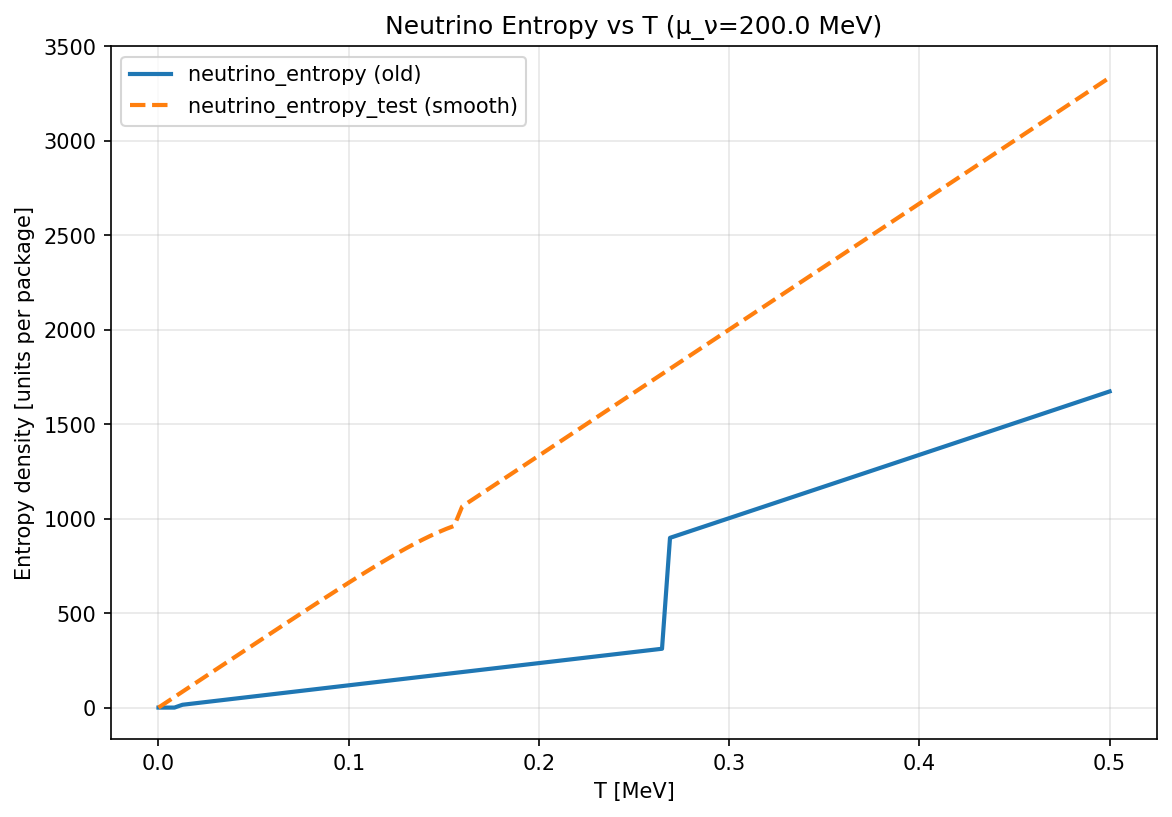

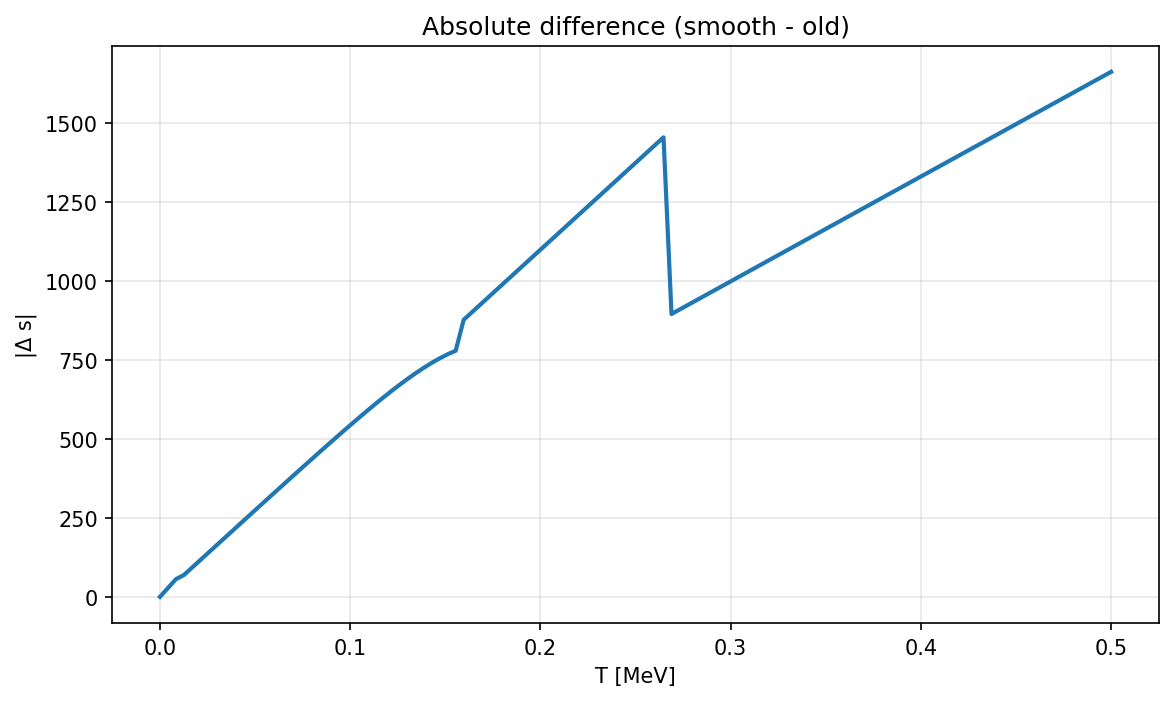

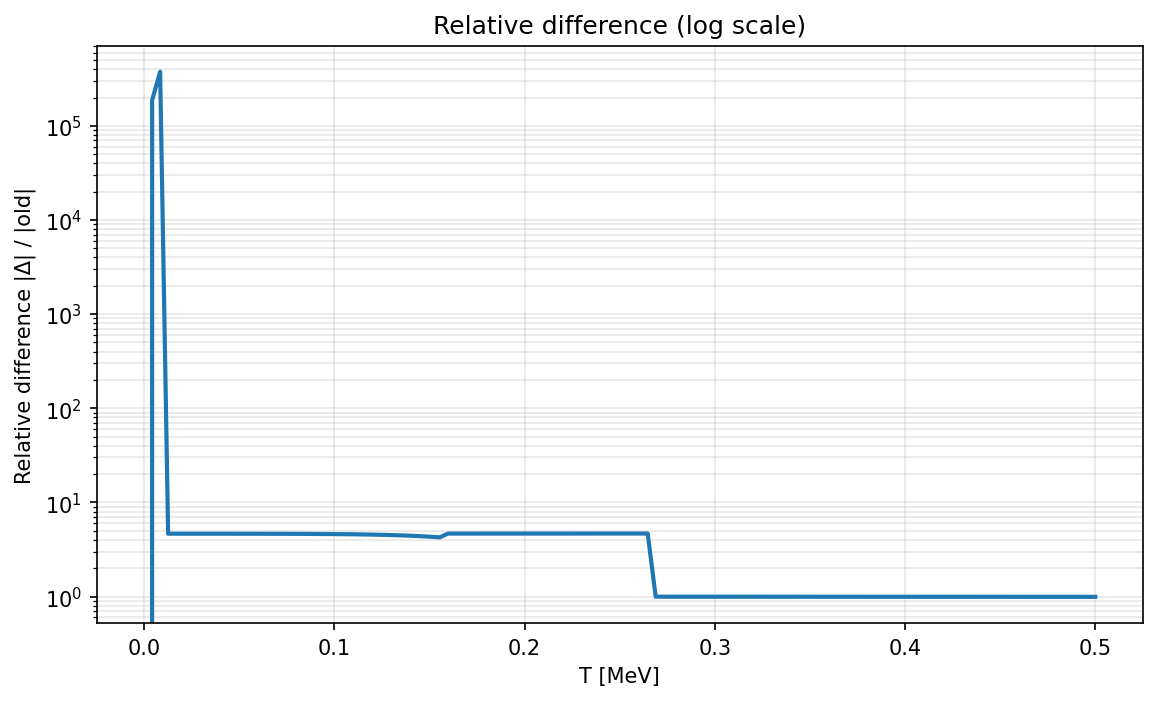

In [150]:
# --- Configuration ---
mu_nu_choice = 200.0        # MeV (neutrino chemical potential)
up_choice    = 4000 # or 4000.0 to match legacy runs

# --- Imports ---
import numpy as np
import matplotlib.pyplot as plt
from RMFsolver.Solver import neutrino_entropy as neutrino_entropy_old

# new smooth version should already be defined as neutrino_entropy_test in this notebook

# --- Temperature grid (uniform) ---
TT = np.linspace(0.0, 0.5, 120)

# --- Evaluate both versions ---
S_old = np.empty_like(TT)
S_new = np.empty_like(TT)

for i, T in enumerate(TT):
    try:
        S_old[i] = neutrino_entropy_old(T, mu_nu_choice, up=up_choice)
    except TypeError:
        S_old[i] = neutrino_entropy_old(T, mu_nu_choice)
    S_new[i] = neutrino_entropy_test(T, mu_nu_choice, up=up_choice)

# --- Differences ---
abs_diff = np.abs(S_new - S_old)
denom    = np.maximum(1e-30, np.abs(S_old))
rel_diff = abs_diff / denom

imax_abs = int(np.argmax(abs_diff))
imax_rel = int(np.argmax(rel_diff))
print(f"Max ABS diff: {abs_diff[imax_abs]:.6e} at T = {TT[imax_abs]:.6f} MeV")
print(f"Max REL diff: {rel_diff[imax_rel]:.6e} at T = {TT[imax_rel]:.6f} MeV")
print(f"At T_abs-max: S_old = {S_old[imax_abs]:.6e}, S_new = {S_new[imax_abs]:.6e}")

# --- Plots ---
plt.figure(figsize=(9,6))
plt.plot(TT, S_old, label="neutrino_entropy (old)", lw=2)
plt.plot(TT, S_new, label="neutrino_entropy_test (smooth)", lw=2, ls="--")
plt.xlabel("T [MeV]")
plt.ylabel("Entropy density [units per package]")
plt.title(f"Neutrino Entropy vs T (μ_ν={mu_nu_choice} MeV)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(9,5))
plt.plot(TT, abs_diff, lw=2)
plt.xlabel("T [MeV]")
plt.ylabel("|Δ s|")
plt.title("Absolute difference (smooth - old)")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(9,5))
plt.plot(TT, rel_diff, lw=2)
plt.xlabel("T [MeV]")
plt.ylabel("Relative difference |Δ| / |old|")
plt.title("Relative difference (log scale)")
plt.yscale("log")
plt.grid(True, which="both", alpha=0.3)
plt.show()

In [154]:
def nucleon_pressure_test(T, mu, sigma, w0, r03, BI):
    """
    Pressure of a baryon species in RMF.

    Parameters:
    T      : temperature (MeV)
    mu     : baryon chemical potential (MeV)
    sigma  : scalar mean field
    w0     : vector mean field
    r03    : isovector mean field
    BI     : baryon index

    Returns:
    float : pressure (MeV^4)
    """
    import numpy as np
    from scipy.integrate import quad

    m_eff = mB[BI] - gs[BI] * sigma
    mu_eff = mu - gw[BI] * w0 - gr[BI] * I3[BI] * r03

    T = float(T); mu_eff = float(mu_eff); m_eff = float(m_eff)

    # T = 0 branch
    if T <= 0.0:
        if mu_eff <= m_eff or m_eff <= 0.0:
            return 0.0
        kF = np.sqrt(max(mu_eff*mu_eff - m_eff*m_eff, 0.0))
        Ef = np.sqrt(kF*kF + m_eff*m_eff)
        term1 = (2.0/3.0 * kF**3 - m_eff*m_eff * kF) * Ef
        term2 = m_eff**4 * np.log((kF + Ef) / max(m_eff, 1e-300))
        return (term1 + term2) / (8.0 * np.pi**2)

    # Sommerfeld low-T
    if mu_eff > m_eff and m_eff > 0.0:
        kF0 = np.sqrt(max(mu_eff*mu_eff - m_eff*m_eff, 0.0))
        Ef0 = np.sqrt(kF0*kF0 + m_eff*m_eff)
        P0  = ((2.0/3.0 * kF0**3 - m_eff*m_eff * kF0) * Ef0
               + m_eff**4 * np.log((kF0 + Ef0) / max(m_eff, 1e-300))) / (8.0 * np.pi**2)
        f_mu = (mu_eff * kF0) / (np.pi**2) if kF0 > 0.0 else 0.0
        P_low = P0 + (np.pi**2/6.0) * (T*T) * f_mu
    else:
        P_low = 0.0

    # Exact finite-T integral
    def integrand(k):
        E = np.sqrt(k*k + m_eff*m_eff)
        a = np.clip((E - mu_eff)/T, -700.0, 700.0)
        b = np.clip((E + mu_eff)/T, -700.0, 700.0)
        arg  = T * np.log1p(np.exp(-a))
        argb = T * np.log1p(np.exp(-b))
        return (arg + argb) * k*k

    try:
        ub = float(upB)
        if not np.isfinite(ub): ub = np.inf
    except Exception:
        ub = np.inf

    Pint, _ = quad(integrand, 0.0, ub, epsabs=1e-10, epsrel=1e-8, limit=200)
    P_int = Pint / (np.pi**2)

    # Smooth blend (more conservative near T~0)
    tiny = 1e-12
    delta = (mu_eff - m_eff) / max(T, tiny)

    # hard gate in the deeply degenerate, tiny-T corner to avoid the valley
    if (T < 0.03) or (delta > 14.0):
        w = 0.0
    else:
        # sharper logistics so w≈0 sooner
        x = np.clip(delta - 12.0, -700.0, 700.0)        # was (delta-8)
        w_deg = 1.0 / (1.0 + np.exp(x))
        y = np.clip(-(T - 0.10)*16.0/0.10, -700.0, 700.0)  # was T0=0.2, sharp=8
        w_T  = 1.0 / (1.0 + np.exp(y))
        w = 1.0 - (1.0 - w_deg)*(1.0 - w_T)
        w = float(np.clip(w, 0.0, 1.0))

    return (1.0 - w)*P_low + w*P_int

Max ABS diff: 3.195723e+02 at T = 0.099160 MeV
Max REL diff: 2.665485e-05 at T = 0.099160 MeV
At T_abs-max: P_old = 1.198927e+07, P_new = 1.198959e+07


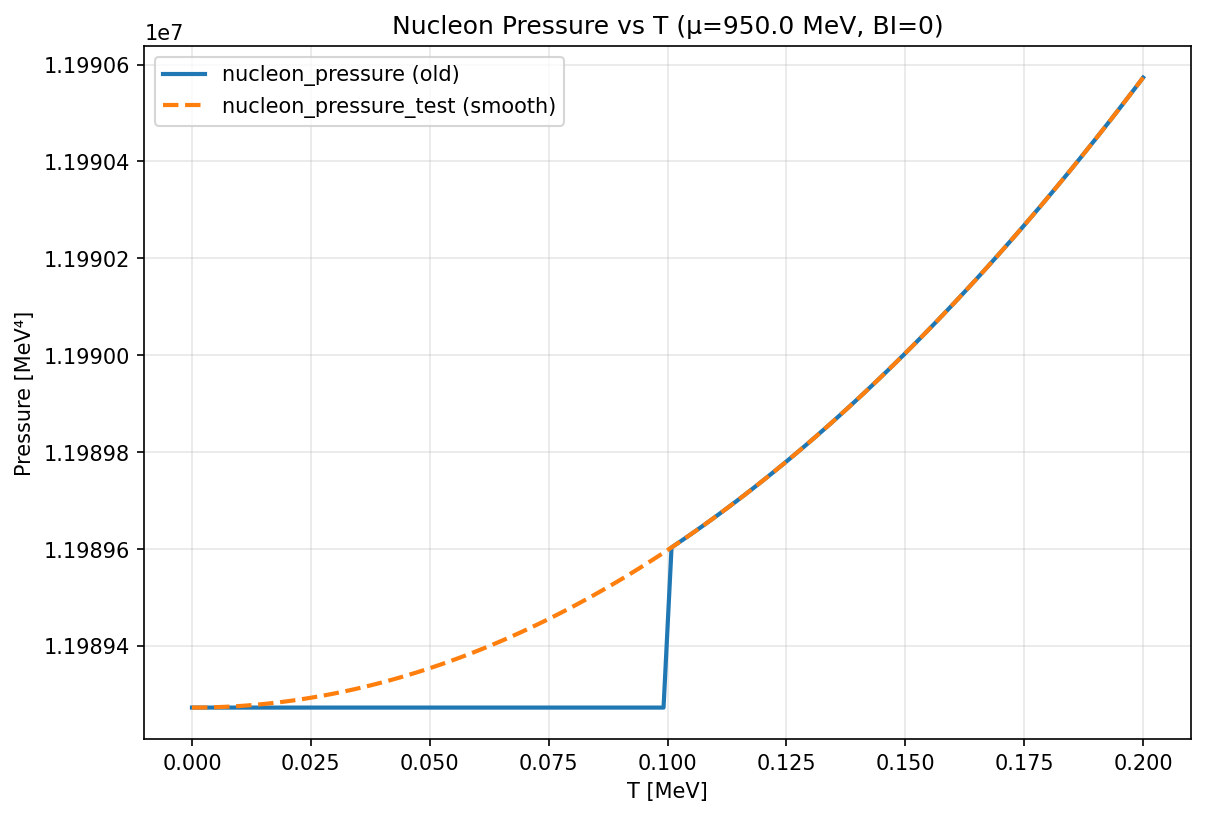

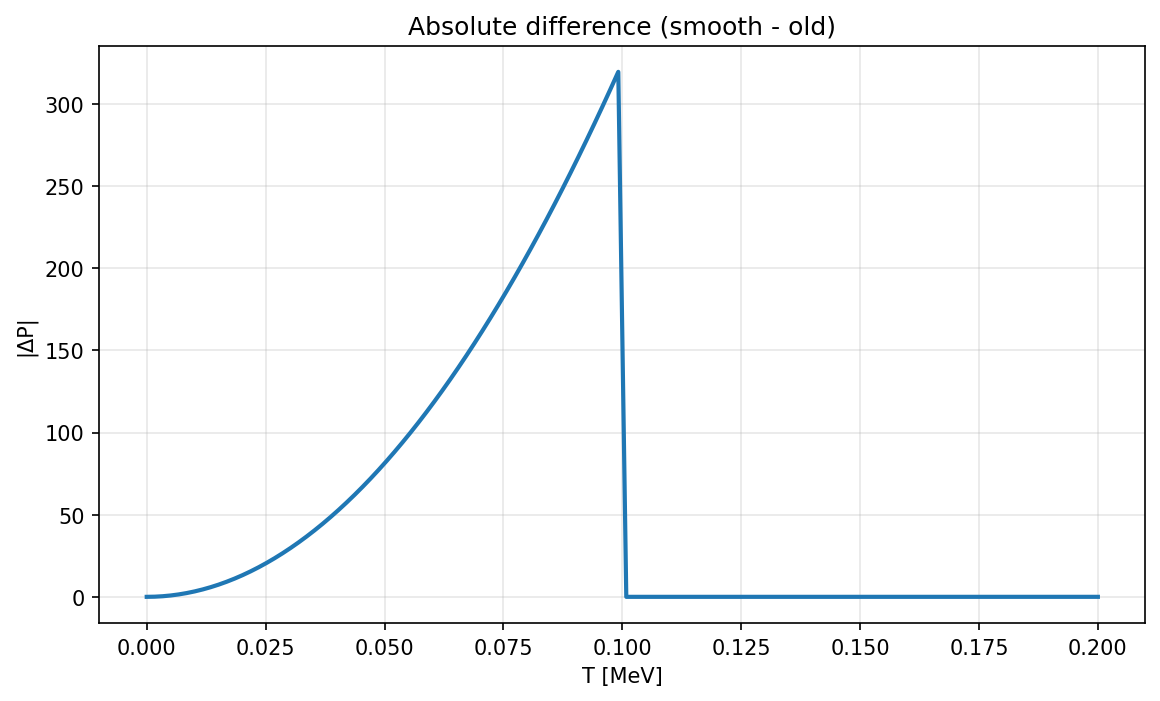

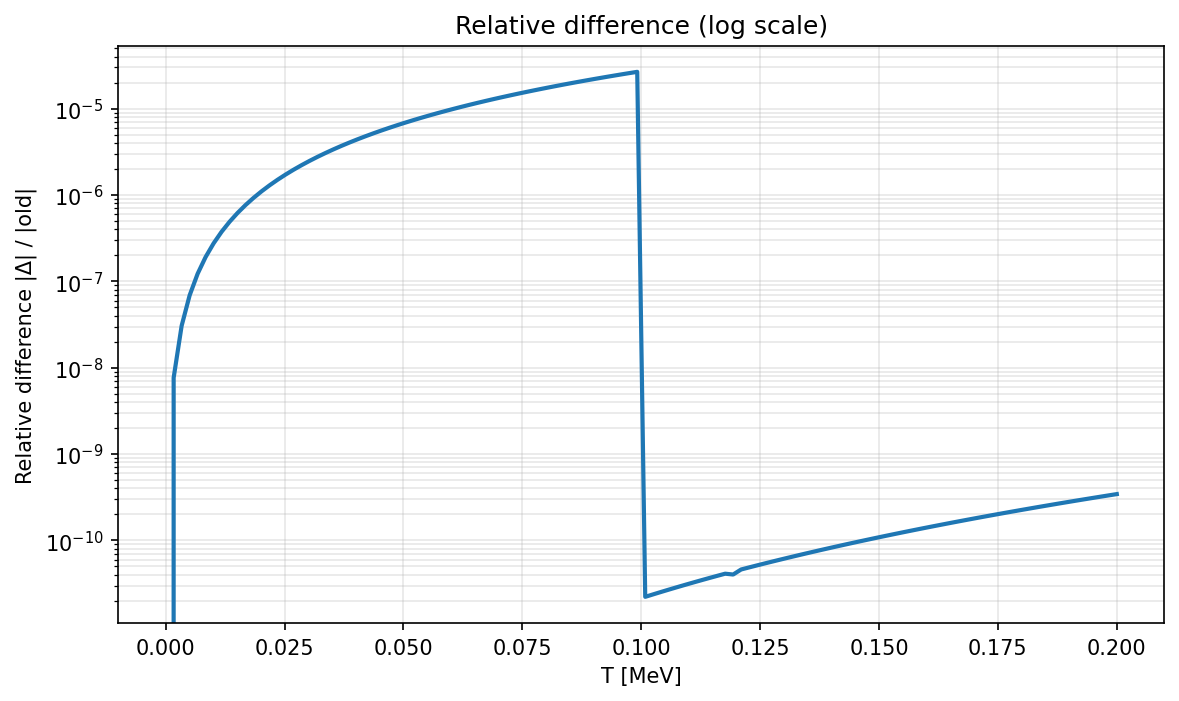

In [156]:
# --- Configuration ---
BI_choice     = 0        # baryon index: 0 for proton, 1 for neutron
mu_choice     = 950.0    # typical μ_B (MeV)
sigma_choice  = 30.0     # mean-field σ (MeV)
w0_choice     = 20.0     # mean-field ω₀ (MeV)
r03_choice    = -3.0     # mean-field ρ₀³ (MeV)
upB_choice    = float('inf')

# --- Imports ---
import numpy as np
import matplotlib.pyplot as plt
from RMFsolver.Solver import nucleon_pressure as nucleon_pressure_old

# new smooth version should already be defined as nucleon_pressure_test in this notebook

# --- Temperature grid ---
TT = np.linspace(0.0, 0.2, 120)

# --- Evaluate both versions ---
P_old = np.empty_like(TT)
P_new = np.empty_like(TT)

for i, T in enumerate(TT):
    try:
        P_old[i] = nucleon_pressure_old(T, mu_choice, sigma_choice, w0_choice, r03_choice, BI_choice)
    except TypeError:
        # in case older signature requires upB
        P_old[i] = nucleon_pressure_old(T, mu_choice, sigma_choice, w0_choice, r03_choice, BI_choice)
    P_new[i] = nucleon_pressure_test(T, mu_choice, sigma_choice, w0_choice, r03_choice, BI_choice)

# --- Differences ---
abs_diff = np.abs(P_new - P_old)
denom    = np.maximum(1e-30, np.abs(P_old))
rel_diff = abs_diff / denom

imax_abs = int(np.argmax(abs_diff))
imax_rel = int(np.argmax(rel_diff))
print(f"Max ABS diff: {abs_diff[imax_abs]:.6e} at T = {TT[imax_abs]:.6f} MeV")
print(f"Max REL diff: {rel_diff[imax_rel]:.6e} at T = {TT[imax_rel]:.6f} MeV")
print(f"At T_abs-max: P_old = {P_old[imax_abs]:.6e}, P_new = {P_new[imax_abs]:.6e}")

# --- Plot results ---
plt.figure(figsize=(9,6))
plt.plot(TT, P_old, label="nucleon_pressure (old)", lw=2)
plt.plot(TT, P_new, label="nucleon_pressure_test (smooth)", lw=2, ls="--")
plt.xlabel("T [MeV]")
plt.ylabel("Pressure [MeV⁴]")
plt.title(f"Nucleon Pressure vs T (μ={mu_choice} MeV, BI={BI_choice})")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(9,5))
plt.plot(TT, abs_diff, lw=2)
plt.xlabel("T [MeV]")
plt.ylabel("|ΔP|")
plt.title("Absolute difference (smooth - old)")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(9,5))
plt.plot(TT, rel_diff, lw=2)
plt.xlabel("T [MeV]")
plt.ylabel("Relative difference |Δ| / |old|")
plt.title("Relative difference (log scale)")
plt.yscale("log")
plt.grid(True, which="both", alpha=0.3)
plt.show()

In [157]:
from RMFsolver.phase_velocity import vNtoQ_nc

start = time.time()
v, _ = vNtoQ_nc(
    T = 0.01,
    n_crit = 3*n0, 
    Deln = 0.2*n0,
    m_s = 0,
    param = para.paraQMCRMF3,
    NM_type = "PNM",
)
end = time.time()

v, end - start

(np.float64(21350.120131351166), 2.0776219367980957)

In [4]:
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.phase_velocity import vNtoQ_nc
import time

n0 = 0.16 * const.MeV_fm**3

start = time.time()
v, _ = vNtoQ_nc(
    T = 2,
    n_crit = 3*n0, 
    Deln = 0.2*n0,
    m_s = 0,
    param = para.paraQMCRMF3,
    NM_type = "PNM",
    #method = "numerical"
)
end = time.time()

v, end - start

(np.float64(240.01699761256455), 7.8544230461120605)

In [2]:
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.phase_velocity import vNtoQ_nc
import time

n0 = 0.16 * const.MeV_fm**3

start = time.time()
v, _ = vNtoQ_nc(
    T = 2,
    n_crit = 3*n0, 
    Deln = 0.2*n0,
    m_s = 0,
    param = para.paraQMCRMF3,
    NM_type = "PNM",
    method = "analytical"
)
end = time.time()

v, end - start

(np.float64(240.01534106295932), 7.890593767166138)

In [5]:
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt
from RMFsolver.phase_velocity import vNtoQ_nc
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para

n0 = 0.16 * const.MeV_fm**3

T_list = np.logspace(-2, np.log10(15), 20)
ve = []
for tt in tqdm(T_list):
    tmp, _ = vNtoQ_nc(
        T = tt,
        n_crit = 3*n0, 
        Deln = 0.15*n0,
        m_s = 0,
        param = para.paraQMCRMF3,
        NM_type = "PNM",
        #method = "numerical"
    )
    ve.append(tmp)

100%|█████████████████████████████████████████████████████████| 20/20 [03:18<00:00,  9.90s/it]


Text(0, 0.5, 'velocity')

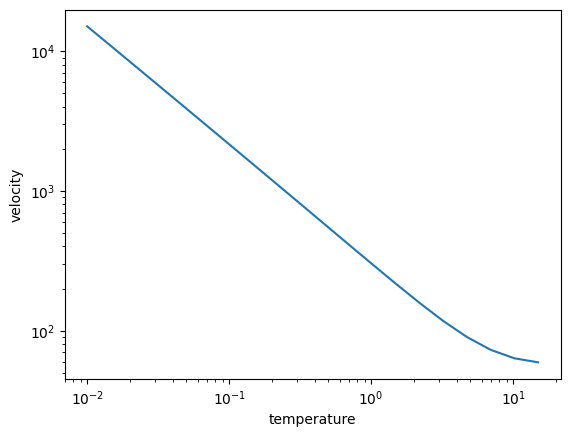

In [6]:
plt.plot(T_list, ve)
plt.yscale("log")
plt.xscale("log")
plt.xlabel("temperature")
plt.ylabel("velocity")

In [2]:
from RMFsolver.Solver import RMFpressurePNM

TT = np.logspace(-3, 1, 20)
PP = np.array([RMFpressurePNM(
    1000,
    "muB",
    TT[i],
    para = para.paraQMCRMF3,
) for i in range(20)])

Text(0, 0.5, 'nucleon pressure')

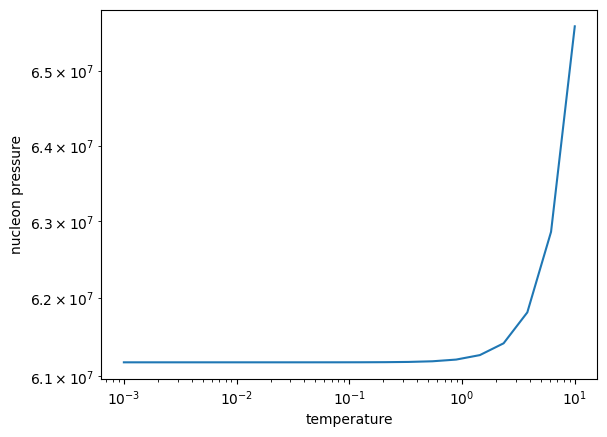

In [3]:
plt.plot(TT, PP)
plt.yscale("log")
plt.xscale("log")
plt.xlabel("temperature")
plt.ylabel("nucleon pressure")

In [28]:
RMFpressurePNM(
    1000,
    "muB",
    1e-10,
    para = para.paraQMCRMF3,
)/1e7

np.float64(6.117769250179068)

In [4]:
RMFpressurePNM(
    1000,
    "muB",
    1e-10,
    para = para.paraQMCRMF3,
)/1e7

np.float64(6.117769250179068)

In [31]:
import numpy as np
from scipy.integrate import quad

# ---- tiny, shared primitives (reused across your module) ----
def _Ek(k: float, m: float) -> float:
    return np.sqrt(k*k + m*m)

def _kF(mu: float, m: float) -> float:
    dm = mu*mu - m*m
    return np.sqrt(dm) if dm > 0.0 else 0.0

def _log1p_exp_neg(a: float) -> float:
    # stable log(1 + exp(-a))
    if a > 50.0:   # very positive -> exp(-a) is tiny
        return np.exp(-a)
    if a < -50.0:  # very negative -> log(1 + e^{-a}) ~ -a
        return -a
    return np.log1p(np.exp(-a))

def _smoothstep01(x: float) -> float:
    # C^1 smooth blend on [0,1]
    x = 0.0 if x < 0.0 else (1.0 if x > 1.0 else x)
    return x*x*(3.0 - 2.0*x)

# ---- single shared helper: adaptive T-switch for free-fermion pressure ----
def Tswitch_free_pressure(mu: float, m: float, rtol: float = 1e-6, band: float = 1.25) -> tuple[float, float]:
    """
    Return (T_lo, T_hi) to blend T=0 pressure with the finite-T integral.

    Logic:
    - If mu <= m (non-degenerate): the T=0 formula gives 0 and is not useful;
      force integral by returning (0, 0).
    - If mu > m (degenerate): set a conservative switch where the O(T^2) term
      would change P by ≲ rtol*P0. This uses only two closed-form scalars:
        P0 = exact T=0 pressure, and f(μ,m) = μ kF / π^2  (massless => μ^2/π^2).
      Then T* = sqrt( (6 rtol P0) / (π^2 f) ), and we blend over [T*/band, T*·band].
    """
    mu = float(mu); m = float(m)

    if mu <= m:
        return (0.0, 0.0)  # integral only

    # exact T=0 pressure, P0
    if m == 0.0:
        P0 = mu**4 / (12.0*np.pi**2)
        f  = (mu*mu) / (np.pi**2)  # coefficient for the O(T^2) correction
    else:
        kF = _kF(mu, m)
        # P0 = [ (2kF^3/3 - m^2 kF) E_F + m^4 ln((kF+E_F)/m ) ] / (8π^2), E_F = sqrt(kF^2 + m^2) = μ
        P0 = ((2.0/3.0 * kF**3 - m*m * kF) * mu + m**4 * np.log((kF + mu) / max(m, 1e-300))) / (8.0*np.pi**2)
        f  = (mu * kF) / (np.pi**2)

    if P0 <= 0.0 or f <= 0.0:
        return (0.0, 0.0)  # fall back to integral if something is off

    T_star = np.sqrt((6.0 * rtol * P0) / (np.pi**2 * f))
    return (T_star / band, T_star * band)

def P_f_test(mu: float, m: float, T: float, upB=np.inf, rtol: float = 1e-6) -> float:
    """
    Pressure of a single free fermion (particles + antiparticles).
    Uses T=0 closed form for T below a tiny switch band, finite-T integral above,
    and a smoothstep blend across the band (log T).
    """
    mu = float(mu); m = float(m); T = float(T)

    # ---- exact T=0 pressure (closed form) ----
    if T <= 0.0:
        if mu <= m:
            return 0.0
        if m == 0.0:
            return mu**4 / (12.0*np.pi**2)
        kF = _kF(mu, m)
        return ((2.0*kF**3 - 3.0*m*m*kF)*mu + 3.0*m**4*np.log((kF + mu)/max(m, 1e-300))) / (24.0*np.pi**2)

    # ---- adaptive switch band ----
    T_lo, T_hi = Tswitch_free_pressure(mu, m, rtol=rtol, band=1.25)

    # ---- pure T=0 or pure integral if outside the band ----
    if T_hi == 0.0:  # non-degenerate or fallback -> use integral everywhere
        use_blend = False
    else:
        use_blend = (T_lo < T < T_hi)

    if not use_blend and T <= T_lo:
        # T=0 closed form again
        if mu <= m:
            return 0.0
        if m == 0.0:
            return mu**4 / (12.0*np.pi**2)
        kF = _kF(mu, m)
        return ((2.0*kF**3 - 3.0*m*m*kF)*mu + 3.0*m**4*np.log((kF + mu)/max(m, 1e-300))) / (24.0*np.pi**2)

    # finite-T integral
    def _P_int(temp: float) -> float:
        def integrand(k):
            Ek = _Ek(k, m)
            a  = (Ek - mu)/temp
            b  = (Ek + mu)/temp
            return temp * (_log1p_exp_neg(a) + _log1p_exp_neg(b)) * (k*k)
        ub = np.inf if (upB is None or not np.isfinite(float(upB))) else float(upB)
        Pint, _ = quad(integrand, 0.0, ub, epsabs=1e-10, epsrel=1e-8, limit=200)
        return Pint / (np.pi**2)

    if not use_blend and T >= T_hi:
        return _P_int(T)

    # ---- blend inside the band on log T ----
    P0 = (
        0.0 if mu <= m else
        (mu**4 / (12.0*np.pi**2) if m == 0.0 else
         (lambda kF: ((2.0*kF**3 - 3.0*m*m*kF)*mu + 3.0*m**4*np.log((kF + mu)/max(m,1e-300))) / (24.0*np.pi**2))(_kF(mu, m)))
    )
    P_int = _P_int(T)

    # map T ∈ [T_lo, T_hi] → x ∈ [0,1] using log scale
    x = (np.log(T) - np.log(T_lo)) / (np.log(T_hi) - np.log(T_lo))
    w = _smoothstep01(x)
    return (1.0 - w)*P0 + w*P_int

In [19]:
from RMFsolver.phase_velocity import P_f, n_B#, _P_f_new, _n_B_new
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

TT = np.logspace(-5,-2,15)
PP = []
nn = []
#PP_new = []
#PP_test = []
for i in tqdm(range(15)):
    #tmp_new = _P_f_new(mu=800, m=0.511, Tem=TT[i], )
    tmp = P_f(mu=800, m=0.511, Tem=TT[i], )
    #tmp_test = P_f_test(mu=800, m=0.511, T=TT[i], )
    tmpn = n_B(mu=800, m=0.511, Tem=TT[i], )
    #PP_new.append(tmp_new)
    PP.append(tmp)
    nn.append(tmpn)
    #PP_test.append(tmp_test)

100%|████████████████████████████████████████████████████████| 15/15 [00:00<00:00, 490.11it/s]


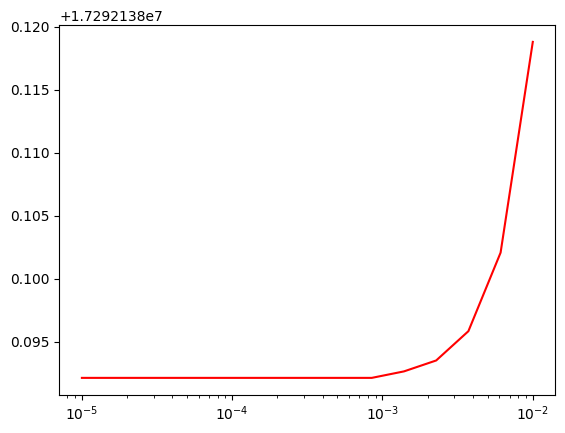

In [20]:
#plt.plot(TT, PP)
plt.plot(TT, nn, 'r')
#plt.plot(TT, PP_test, 'g')
plt.xscale('log')

In [5]:
np.exp(-(200/0.1))

np.float64(0.0)

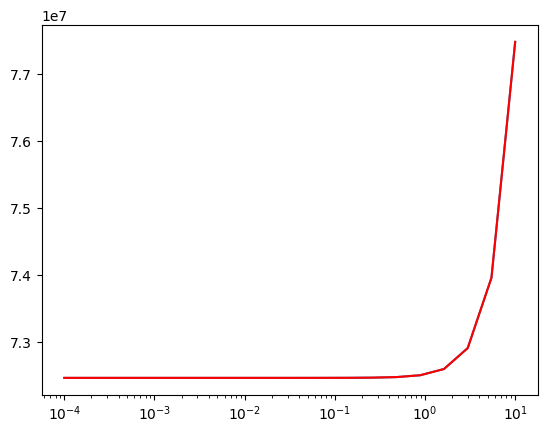

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from RMFsolver.Solver import nucleon_pressure, _set_couplings
import RMFsolver.RMFparameter as para

# --- Configuration ---
BI_choice    = 0            # 0: proton, 1: neutron
muB_choice   = 1000.0       # MeV
sigma_choice = 30.0         # MeV
w0_choice    = 20.0         # MeV
r03_choice   = -3.0         # MeV
upB_choice   = float('inf') # or 5000.0

# initialize couplings
_set_couplings(para.paraQMCRMF3)

# expose the global arrays so _ns_test can access them
from RMFsolver.Solver import mB, gs, gw, gr, I3

TT = np.logspace(-4, 1, 20)
nn = np.array([nucleon_pressure(TT[i], muB_choice, sigma_choice, w0_choice, r03_choice, BI_choice) for i in range(20)])
nn_test = np.array([nucleon_pressure_test(TT[i], muB_choice, sigma_choice, w0_choice, r03_choice, BI_choice) for i in range(20)])

plt.plot(TT, nn)
plt.plot(TT, nn_test, 'r')
plt.xscale('log')

In [1]:
import numpy as np
from scipy.integrate import quad

# ---------- tiny helpers (reusable in Solver.py) ----------
def _Ek(k: float, m: float) -> float:
    return np.sqrt(k*k + m*m)

def _kF(mu: float, m: float) -> float:
    dm = mu*mu - m*m
    return np.sqrt(dm) if dm > 0.0 else 0.0

def _log1p_exp_neg(a: float) -> float:
    # stable log(1 + exp(-a))
    if a > 50.0:
        return np.exp(-a)
    if a < -50.0:
        return -a
    return np.log1p(np.exp(-a))

def _smoothstep01(x: float) -> float:
    # C^1 smooth blend on [0,1]
    x = 0.0 if x < 0.0 else (1.0 if x > 1.0 else x)
    return x*x*(3.0 - 2.0*x)

def Tswitch_free_pressure(mu: float, m: float, rtol: float = 1e-6, band: float = 1.25) -> tuple[float, float]:
    """
    Adaptive switch band (T_lo, T_hi) between T=0 formula and finite-T integral
    for a free fermion pressure. If mu <= m, returns (0.0, 0.0) → use integral only.
    """
    mu = float(mu); m = float(m)
    if mu <= m:
        return (0.0, 0.0)

    # exact T=0 pressure P0 and Sommerfeld prefactor f(μ,m)
    if m == 0.0:
        P0 = mu**4 / (12.0*np.pi**2)
        f  = (mu*mu) / (np.pi**2)
    else:
        kF = _kF(mu, m)
        P0 = ((2.0/3.0 * kF**3 - m*m * kF) * mu
              + m**4 * np.log((kF + mu) / max(m, 1e-300))) / (8.0*np.pi**2)
        f  = (mu * kF) / (np.pi**2)

    if P0 <= 0.0 or f <= 0.0:
        return (0.0, 0.0)

    T_star = np.sqrt((6.0 * rtol * P0) / (np.pi**2 * f))
    return (T_star / band, T_star * band)


# ---------- main function ----------
def nucleon_pressure_test(T, mu, sigma, w0, r03, BI, upB=5000):
    """
    Pressure of a baryon species in RMF (single species BI).
    Uses an adaptive T-band (T_lo,T_hi) to blend between the exact T=0
    expression and the finite-T integral, with a smoothstep on log T.

    Parameters
    ----------
    T      : temperature (MeV)
    mu     : baryon chemical potential (MeV)
    sigma  : scalar mean field
    w0     : vector mean field
    r03    : isovector mean field
    BI     : baryon index
    upB    : upper bound for momentum integral (MeV)

    Returns
    -------
    float : pressure (MeV^4)
    """
    # effective mass & chemical potential
    m_eff = float(mB[BI] - gs[BI] * sigma)
    mu_eff = float(mu - gw[BI] * w0 - gr[BI] * I3[BI] * r03)
    T = float(T)

    # -------- exact T = 0 branch (particles only) --------
    if T <= 0.0:
        if (m_eff <= 0.0) or (mu_eff <= m_eff):
            return 0.0
        kF = np.sqrt(max(mu_eff*mu_eff - m_eff*m_eff, 0.0))
        Ef = np.sqrt(kF*kF + m_eff*m_eff)
        term1 = (2.0/3.0 * kF**3 - m_eff*m_eff * kF) * Ef
        term2 = m_eff**4 * np.log((kF + Ef) / max(m_eff, 1e-300))
        return (term1 + term2) / (8.0 * np.pi**2)

    # -------- adaptive switch band (based on tiny Sommerfeld term) --------
    # Note: we only use the band to place the transition; the blend itself
    # is between the exact T=0 formula and the finite-T integral.
    T_lo, T_hi = Tswitch_free_pressure(mu_eff, m_eff, rtol=1e-6, band=1.25)
    use_blend = (T_lo < T < T_hi) if (T_hi > 0.0) else False

    # Below the band → use T=0 formula
    if not use_blend and (T <= T_lo):
        if (m_eff <= 0.0) or (mu_eff <= m_eff):
            return 0.0
        kF = np.sqrt(max(mu_eff*mu_eff - m_eff*m_eff, 0.0))
        Ef = np.sqrt(kF*kF + m_eff*m_eff)
        term1 = (2.0/3.0 * kF**3 - m_eff*m_eff * kF) * Ef
        term2 = m_eff**4 * np.log((kF + Ef) / max(m_eff, 1e-300))
        return (term1 + term2) / (8.0 * np.pi**2)

    # -------- finite-T integral (stable) --------
    def _P_int(Tloc: float) -> float:
        # P = ∫_0^∞ T [log(1+e^{-(E-μ)/T}) + log(1+e^{-(E+μ)/T})] k^2 dk / π^2
        def integrand(k):
            E = np.sqrt(k*k + m_eff*m_eff)
            a = (E - mu_eff) / Tloc
            b = (E + mu_eff) / Tloc
            return Tloc * (_log1p_exp_neg(a) + _log1p_exp_neg(b)) * (k*k)
        try:
            ub = float(upB)
            if not np.isfinite(ub): ub = np.inf
        except Exception:
            ub = np.inf
        Pint, _ = quad(integrand, 0.0, ub, epsabs=1e-10, epsrel=1e-8, limit=200)
        return Pint / (np.pi**2)

    # Above the band → use integral only
    if not use_blend and (T >= T_hi):
        return _P_int(T)

    # -------- inside the band: smooth blend on log T --------
    # exact T=0 pressure (as above)
    if (m_eff <= 0.0) or (mu_eff <= m_eff):
        P0 = 0.0
    else:
        kF = np.sqrt(max(mu_eff*mu_eff - m_eff*m_eff, 0.0))
        Ef = np.sqrt(kF*kF + m_eff*m_eff)
        term1 = (2.0/3.0 * kF**3 - m_eff*m_eff * kF) * Ef
        term2 = m_eff**4 * np.log((kF + Ef) / max(m_eff, 1e-300))
        P0 = (term1 + term2) / (8.0 * np.pi**2)

    Pint = _P_int(T)
    x = (np.log(T) - np.log(T_lo)) / (np.log(T_hi) - np.log(T_lo))
    w = _smoothstep01(x)
    return (1.0 - w)*P0 + w*Pint

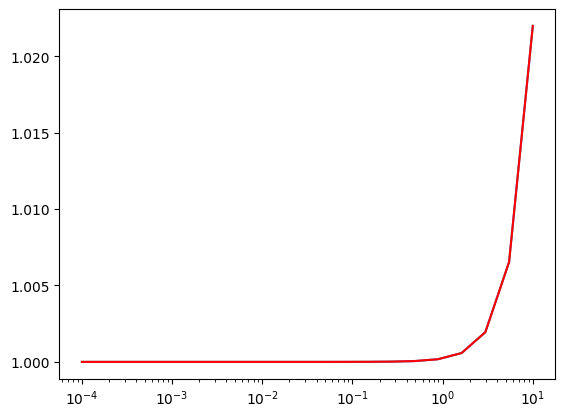

In [2]:
from RMFsolver.Solver import n_electron, neutrino_pressure, n_neutrino
import numpy as np
import matplotlib.pyplot as plt

TT = np.logspace(-4, 1, 20)
pp = np.array([neutrino_pressure(TT[i], 300) for i in range(20)])/neutrino_pressure(0, 300)
pp_test = np.array([neutrino_pressure_test(TT[i], 300) for i in range(20)])/neutrino_pressure_test(0, 300)

plt.plot(TT, pp)
plt.plot(TT, pp_test, 'r')
plt.xscale('log')

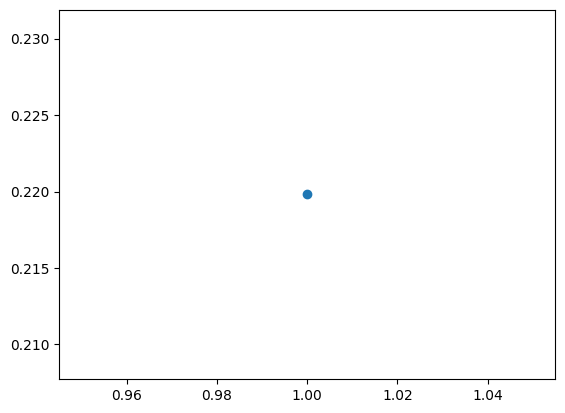

In [9]:
import numpy as np
import matplotlib.pyplot as plt

T_list = [1]
aQstar = 0.3
aN=1.0 
muQ=360

alpha_s = 0.3
g_s = np.sqrt(4 * np.pi * alpha_s)

ratio = []
part1_list = []
part2_list = []

for T in T_list:
    # Compute intermediate quantities
    etaQ = (9 * np.pi**2 * T**2) / muQ**2
    tauQ = 1.98e12 * ((300 / muQ)**5)
    qD = np.sqrt(3 * g_s**2 * muQ**2 / (2 * np.pi**2))
    h = 1.81317
    
    part1 = h*T**(5/3)/qD**(2/3)
    part2 = np.pi**3 * T**2 / (12*qD)
    
    DQ = 1/( 24*alpha_s**2/np.pi * ( part1 + part2 ) )
    ratio.append(part2/part1)
    part1_list.append(part1)
    part2_list.append(part2)

plt.scatter(T_list, ratio)
#plt.plot(T_list, part1_list, 'r-')
#plt.plot(T_list, part2_list, 'g.')
#plt.yscale('log')
#plt.xscale('log')